<a href="https://colab.research.google.com/github/kirtiiiiiii/Landslide-detection/blob/main/GLaD4CD_Landslide_Change_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 4 — Landslide Change Detection from Pre- and Post-Event Sentinel-2 Pairs (GLaD4CD)
**Module:** Risk Modeling — Landslide Detection (change detection)  
**Dataset:** GLaD4CD v2.0 (Politecnico di Milano, CC BY 4.0), Zenodo record 14226448. The event catalogue comes from the v1 record 10800338.

**How to run:** Runtime → Change runtime type → **T4 GPU**, then *Run all* (budget ≤ 30 min; the 295 MB download takes about 6 min).  
Cells depend on earlier cells, so run them in order.

### Where each requirement of the brief is answered
| Brief requirement | Section |
|---|---|
| Inspect folder structure, confirm which folders have labels | 0.3, 1.1 |
| Parse event CSV: country, trigger, pre/post time gap, South Asia | 1.8 |
| Pre/post pair size and georeferencing check | 1.2, 1.5 |
| Mask no-data, normalise bands | 1.5 |
| Change features: concatenated bands, absolute difference, NDVI/BSI differences | 1.9 (built), 6.1 (tested) |
| 64×64 crops, share of changed pixels per pair, no pair in both train and validation | 1.5, 1.7 |
| **Coding 1:** NDVI differencing and change-vector analysis with Otsu, IoU/F1 per pair | 2 |
| **Coding 2:** early-fusion U-Net and Siamese U-Net, grouped 4-fold CV | 3 |
| **Coding 3 (optional):** self-supervised pre-training on unlabelled TRAIN patches | 6.2 |
| **Coding 4:** mean ± std of IoU/F1, best/worst pair panels | 4 |
| Reflection evidence | see the map at the end of the notebook |

## 0. Setup
Install libraries, download the dataset from Zenodo (MD5-verified) and extract it.

In [ ]:
# @title 0.1 Install libraries
!pip -q install rasterio geopandas scikit-learn pandas numpy matplotlib seaborn tqdm

print("All required libraries installed successfully!")


All required libraries installed successfully!


In [ ]:
# @title 0.2 Download GLaD4CD v2.0 from Zenodo (MD5 verified)
import os
import requests
import zipfile
import hashlib
from tqdm.auto import tqdm

BASE_DIR = "/content/GLAD4CD"
ZIP_PATH = "/content/GLaD4CD_2.0.zip"

os.makedirs(BASE_DIR, exist_ok=True)

DATA_URL = (
    "https://zenodo.org/records/14226448/files/"
    "GLaD4CD_2.0.zip?download=1"
)

print("Downloading GLaD4CD dataset...")

if not os.path.exists(ZIP_PATH):
    response = requests.get(DATA_URL, stream=True, timeout=120)
    response.raise_for_status()

    total = int(response.headers.get("content-length", 0))

    with open(ZIP_PATH, "wb") as f:
        with tqdm(total=total, unit="B", unit_scale=True) as pbar:
            for chunk in response.iter_content(chunk_size=1024*1024):
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))

# Verify the official MD5 checksum
md5 = hashlib.md5()

with open(ZIP_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024*1024), b""):
        md5.update(chunk)

actual_md5 = md5.hexdigest()
expected_md5 = "7b317acbf0e98ad6d55550ad4d893557"

print("MD5:", actual_md5)

if actual_md5 != expected_md5:
    raise ValueError("Dataset checksum mismatch. Please download again.")

print("Dataset download and checksum verification successful!")


  0%|          | 0.00/295M [00:00<?, ?B/s]

MD5: 7b317acbf0e98ad6d55550ad4d893557
Dataset download and checksum verification successful!


In [ ]:
# @title 0.3 Extract the zip and show the folder structure
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(BASE_DIR)

print("Dataset extracted successfully!")

# Show folder structure
for root, dirs, files in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, "").count(os.sep)

    if level <= 3:
        indent = " " * 4 * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")

print("\nExtraction completed.")


Dataset extracted successfully!
GLAD4CD/
    GLaD4CD_2.0/
        TEST/
            CM/
                173.png
                164.png
                36.png
                41.png
                61.png
            POST/
                158.tif
                155.tif
                140.tif
                36.tif
                128.tif
            PRE/
                158.tif
                155.tif
                140.tif
                36.tif
                128.tif
        TRAIN/
            POST/
                53.tif
                103.tif
                132.tif
                106.tif
                111.tif
            PRE/
                53.tif
                103.tif
                106.tif
                111.tif
                130.tif

Extraction completed.


## 1. Preprocessing
*Brief — Preprocessing tasks.*

### 1.1 Folder structure, pair matching and labels
TRAIN has PRE/POST only (156 pairs, **no labels**). TEST has PRE/POST and a change map (CM folder) for **17 labelled pairs**. Only the 17 labelled pairs are used for supervised work.

In [ ]:
# @title 1.1 Match PRE/POST pairs and locate the label maps
from pathlib import Path
import pandas as pd
import os

DATA_ROOT = Path("/content/GLAD4CD/GLaD4CD_2.0")

PRE_TRAIN = DATA_ROOT / "TRAIN/PRE"
POST_TRAIN = DATA_ROOT / "TRAIN/POST"

PRE_TEST = DATA_ROOT / "TEST/PRE"
POST_TEST = DATA_ROOT / "TEST/POST"

CM_TEST = DATA_ROOT / "TEST/CM"

def get_files(folder):
    return {
        f.stem: f
        for f in folder.iterdir()
        if f.suffix.lower() in [".tif", ".tiff"]
    }

train_pre = get_files(PRE_TRAIN)
train_post = get_files(POST_TRAIN)

test_pre = get_files(PRE_TEST)
test_post = get_files(POST_TEST)

test_cm = {
    f.stem: f
    for f in CM_TEST.iterdir()
    if f.suffix.lower() == ".png"
}

print("TRAIN PRE:", len(train_pre))
print("TRAIN POST:", len(train_post))
print("TEST PRE:", len(test_pre))
print("TEST POST:", len(test_post))
print("TEST LABELS:", len(test_cm))

pairs = []

# Match training images
for event_id in sorted(set(train_pre) & set(train_post)):
    pairs.append({
        "pair_id": event_id,
        "split": "TRAIN",
        "pre": str(train_pre[event_id]),
        "post": str(train_post[event_id]),
        "label": None
    })

# Match labelled test images
for event_id in sorted(
    set(test_pre) & set(test_post) & set(test_cm)
):
    pairs.append({
        "pair_id": event_id,
        "split": "TEST",
        "pre": str(test_pre[event_id]),
        "post": str(test_post[event_id]),
        "label": str(test_cm[event_id])
    })

pair_df = pd.DataFrame(pairs)

print("\nMATCHED PAIRS:", len(pair_df))
print("TRAIN PAIRS:", (pair_df.split == "TRAIN").sum())
print("LABELLED TEST PAIRS:", (pair_df.split == "TEST").sum())

display(pair_df)

pair_df.to_csv(
    "/content/GLAD4CD/pair_inventory.csv",
    index=False
)

assert len(test_cm) == 17, "Expected 17 test labels."
assert (pair_df.split == "TEST").sum() == 17, (
    "Not all 17 labelled pairs matched. Check filenames."
)

print("\nSUCCESS: All 17 labelled test pairs matched!")


TRAIN PRE: 156
TRAIN POST: 157
TEST PRE: 17
TEST POST: 17
TEST LABELS: 17

MATCHED PAIRS: 173
TRAIN PAIRS: 156
LABELLED TEST PAIRS: 17


,pair_id,split,pre,post,label
0,0,TRAIN,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/PRE/0.tif,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/POST/0.tif,None
1,1,TRAIN,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/PRE/1.tif,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/POST/1.tif,None
2,10,TRAIN,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/PRE/10.tif,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/POST/10.tif,None
3,100,TRAIN,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/PRE/100.tif,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/POST/100.tif,None
4,101,TRAIN,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/PRE/101.tif,/content/GLAD4CD/GLaD4CD_2.0/TRAIN/POST/101.tif,None
...,...,...,...,...,...
168,36,TEST,/content/GLAD4CD/GLaD4CD_2.0/TEST/PRE/36.tif,/content/GLAD4CD/GLaD4CD_2.0/TEST/POST/36.tif,/content/GLAD4CD/GLaD4CD_2.0/TEST/CM/36.png
169,41,TEST,/content/GLAD4CD/GLaD4CD_2.0/TEST/PRE/41.tif,/content/GLAD4CD/GLaD4CD_2.0/TEST/POST/41.tif,/content/GLAD4CD/GLaD4CD_2.0/TEST/CM/41.png
170,42,TEST,/content/GLAD4CD/GLaD4CD_2.0/TEST/PRE/42.tif,/content/GLAD4CD/GLaD4CD_2.0/TEST/POST/42.tif,/content/GLAD4CD/GLaD4CD_2.0/TEST/CM/42.png
171,61,TEST,/content/GLAD4CD/GLaD4CD_2.0/TEST/PRE/61.tif,/content/GLAD4CD/GLaD4CD_2.0/TEST/POST/61.tif,/content/GLAD4CD/GLaD4CD_2.0/TEST/CM/61.png



SUCCESS: All 17 labelled test pairs matched!


### 1.2 Raster quality: size, CRS, georeferencing, bands
Each pair is checked for identical size, CRS, transform and band count. One pair (140) has a different transform; section 1.5 quantifies it and excludes it.

In [ ]:
# @title 1.2 Raster quality checks (size, CRS, transform, bands)
import rasterio
import numpy as np

def inspect_raster(path):
    with rasterio.open(path) as src:
        return {
            "file": os.path.basename(path),
            "width": src.width,
            "height": src.height,
            "bands": src.count,
            "crs": str(src.crs),
            "transform": tuple(src.transform),
            "nodata": src.nodata,
            "descriptions": src.descriptions
        }

quality_results = []

for _, row in pair_df.iterrows():

    pre = inspect_raster(row["pre"])
    post = inspect_raster(row["post"])

    same_size = (
        pre["width"] == post["width"]
        and pre["height"] == post["height"]
    )

    same_crs = pre["crs"] == post["crs"]

    same_transform = np.allclose(
        pre["transform"],
        post["transform"],
        atol=1e-8
    )

    same_bands = pre["bands"] == post["bands"]

    quality_results.append({
        "pair_id": row["pair_id"],
        "same_size": same_size,
        "same_crs": same_crs,
        "same_transform": same_transform,
        "same_bands": same_bands,
        "pre_width": pre["width"],
        "pre_height": pre["height"],
        "pre_bands": pre["bands"]
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)

print("\nQUALITY SUMMARY")
print(quality_df[
    ["same_size", "same_crs",
     "same_transform", "same_bands"]
].sum())

quality_df.to_csv(
    BASE_DIR + "/raster_quality_report.csv",
    index=False
)

# Display descriptions for first pair
first = pair_df.iloc[0]

with rasterio.open(first["pre"]) as src:
    print("\nBand descriptions:", src.descriptions)
    print("Number of bands:", src.count)
    print("CRS:", src.crs)
    print("NoData:", src.nodata)


,pair_id,same_size,same_crs,same_transform,same_bands,pre_width,pre_height,pre_bands
0,0,True,True,True,True,189,231,13
1,1,True,True,True,True,201,246,13
2,10,True,True,True,True,172,210,13
3,100,True,True,True,True,157,192,13
4,101,True,True,True,True,157,191,13
...,...,...,...,...,...,...,...,...
168,36,True,True,True,True,184,225,13
169,41,True,True,True,True,200,244,13
170,42,True,True,True,True,201,246,13
171,61,True,True,True,True,179,218,13



QUALITY SUMMARY
same_size         173
same_crs          173
same_transform    172
same_bands        173
dtype: int64

Band descriptions: ('B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B10', 'B11', 'B12')
Number of bands: 13
CRS: EPSG:32643
NoData: None


### 1.3 Settings

In [ ]:
# @title 1.3 Preprocessing settings
CROP_SIZE = 64             # brief: 64x64 crops
STRIDE = 64                # non-overlapping crops (no pixel appears in two crops)
MIN_VALID_FRACTION = 0.80  # keep a crop only if >= 80% of its pixels are valid in BOTH dates
# Note: the GeoTIFFs have no cloud-mask band, so cloud masking is not applied (stated in the report).

print("Settings ready:", dict(CROP_SIZE=CROP_SIZE, STRIDE=STRIDE, MIN_VALID_FRACTION=MIN_VALID_FRACTION))


Settings ready: {'CROP_SIZE': 64, 'STRIDE': 64, 'MIN_VALID_FRACTION': 0.8}


### 1.4 Label resolution check
The change-map PNGs are 2048×2048, while the Sentinel-2 images are only about 200×240 pixels. The label is resized to the image grid with **nearest-neighbour** interpolation so that it stays binary. The overlay checks that the resized label lines up with the landslide scar.

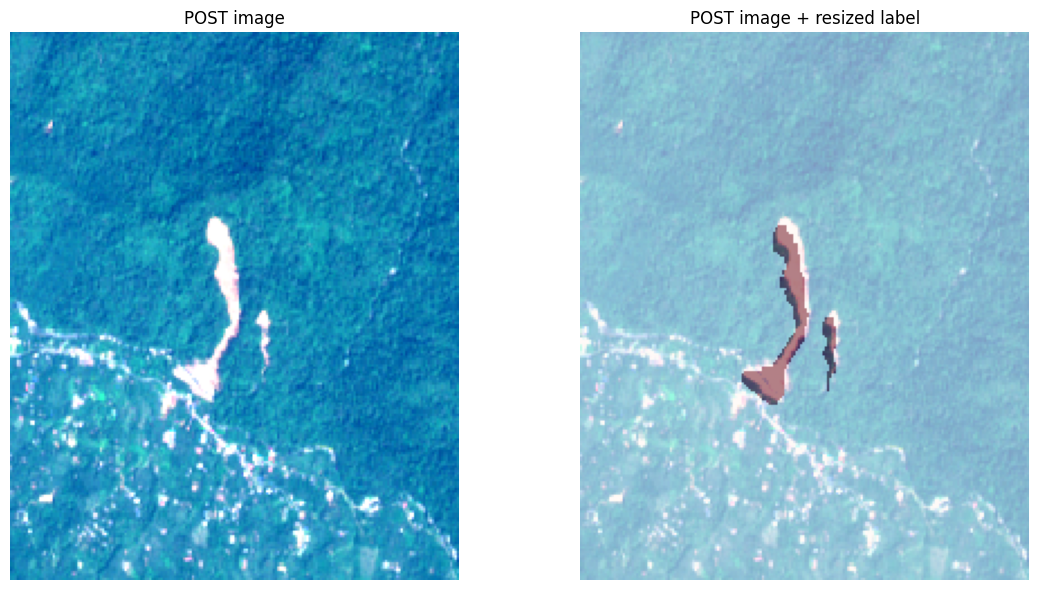

Original label: (2048, 2048)
Resized label: (244, 200)
Label values: [0 1]


In [ ]:
# @title 1.4 Resize a label to the image grid and check the overlay
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from PIL import Image

pair_id = "41"

# Read POST image
with rasterio.open(test_post[pair_id]) as src:
    post = np.stack([
        src.read(4),
        src.read(3),
        src.read(2)
    ], axis=-1).astype(float)

    target_height = src.height
    target_width = src.width

# Read original PNG label
label_original = Image.open(test_cm[pair_id]).convert("L")

# Resize using nearest-neighbour
label_resized = label_original.resize(
    (target_width, target_height),
    Image.Resampling.NEAREST
)

label_resized = np.array(label_resized)

# Display POST and resized label
low, high = np.percentile(post, [2, 98])
post_display = np.clip((post-low)/(high-low+1e-6), 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(post_display)
ax[0].set_title("POST image")

ax[1].imshow(post_display)
ax[1].imshow(
    label_resized,
    cmap="Reds",
    alpha=0.5,
    vmin=0,
    vmax=1
)
ax[1].set_title("POST image + resized label")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

print("Original label:", label_original.size)
print("Resized label:", label_resized.shape)
print("Label values:", np.unique(label_resized))


### 1.5 No-data mask, normalisation, 64×64 crops and changed-pixel share
- **Alignment:** pairs whose PRE/POST origins differ by more than 1 pixel are excluded (pair 140 is about 1461 px off).
- **Mask:** a pixel is valid if it is finite and not all-zero in **both** dates.
- **Normalisation:** joint per-band 2–98 percentile scaling of PRE and POST, so the two dates share one scale.
- **Crops:** 64×64, no overlap, and each crop must have at least 80% valid pixels.
- **Output:** per-pair statistics, including the share of changed pixels, in `pair_stats_df`.

In [ ]:
# @title 1.5 Mask, normalise and cut 64x64 crops; changed-pixel share per pair
import os, glob, warnings
import numpy as np
import pandas as pd
import rasterio
import rasterio.errors
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)

MAX_SHIFT_PX = 1.0   # pairs misaligned by more than this are excluded

OUTPUT_DIR = BASE_DIR + "/processed"
CROP_DIR = OUTPUT_DIR + "/crops"
os.makedirs(CROP_DIR, exist_ok=True)

# Remove crops from any earlier run so no stale files remain
for f in glob.glob(CROP_DIR + "/*.npz"):
    os.remove(f)


def read_scene(path):
    with rasterio.open(path) as src:
        arr = src.read(out_dtype="float32")          # (13, H, W)
        return arr, src.transform, src.height, src.width


def load_label_resized(path, h, w):
    lab = Image.open(path).convert("L").resize((w, h), Image.NEAREST)
    return (np.array(lab) > 0).astype(np.uint8)


def normalise_pair(pre, post, valid):
    """Joint per-band 2-98 percentile normalisation of PRE and POST."""
    pre_n, post_n = np.zeros_like(pre), np.zeros_like(post)
    for b in range(pre.shape[0]):
        vals = np.concatenate([pre[b][valid], post[b][valid]])
        lo, hi = np.percentile(vals, [2, 98]) if vals.size else (0.0, 1.0)
        if hi <= lo:
            hi = lo + 1e-6
        pre_n[b] = np.clip((pre[b] - lo) / (hi - lo), 0, 1)
        post_n[b] = np.clip((post[b] - lo) / (hi - lo), 0, 1)
    return pre_n, post_n


labelled_pairs = pair_df[pair_df["label"].notna()].copy()
print("Labelled pairs to process:", len(labelled_pairs))

crop_records, pair_stats, excluded = [], [], []

for _, row in tqdm(labelled_pairs.iterrows(), total=len(labelled_pairs)):
    pid = str(row["pair_id"])
    pre, pre_tf, ph, pw = read_scene(row["pre"])
    post, post_tf, qh, qw = read_scene(row["post"])

    # Offset between PRE and POST origins, in pixels
    shift_px = max(abs(pre_tf.c - post_tf.c),
                   abs(pre_tf.f - post_tf.f)) / abs(pre_tf.a)

    # Exclusion checks
    if (ph, pw) != (qh, qw) or pre.shape[0] != post.shape[0]:
        reason = "PRE/POST shape mismatch"
    elif shift_px > MAX_SHIFT_PX:
        reason = f"misregistered by {shift_px:.0f} px"
    else:
        reason = None

    if reason:
        print(f"EXCLUDING pair {pid}: {reason}")
        excluded.append({"pair_id": pid, "reason": reason,
                         "transform_shift_px": round(float(shift_px), 2)})
        continue

    label = load_label_resized(row["label"], ph, pw)

    # valid = finite and not all-zero across bands, in BOTH dates
    valid = (np.isfinite(pre).all(0) & np.isfinite(post).all(0)
             & (pre.sum(0) != 0) & (post.sum(0) != 0))
    pre_n, post_n = normalise_pair(np.nan_to_num(pre), np.nan_to_num(post), valid)

    n_crops = 0
    for y in range(0, ph - CROP_SIZE + 1, STRIDE):
        for x in range(0, pw - CROP_SIZE + 1, STRIDE):
            sl = (slice(y, y + CROP_SIZE), slice(x, x + CROP_SIZE))
            if valid[sl].mean() < MIN_VALID_FRACTION:
                continue
            cid = f"{pid}_{y}_{x}"
            path = f"{CROP_DIR}/{cid}.npz"
            np.savez_compressed(
                path,
                pre=pre_n[(slice(None),) + sl].astype(np.float16),
                post=post_n[(slice(None),) + sl].astype(np.float16),
                label=label[sl],
                valid=valid[sl],
            )
            crop_records.append({"crop_id": cid, "pair_id": pid, "path": path,
                                 "changed_frac": float(label[sl].mean())})
            n_crops += 1

    pair_stats.append({"pair_id": pid, "height": ph, "width": pw,
                       "changed_pct": 100 * label.mean(),
                       "valid_pct": 100 * valid.mean(),
                       "transform_shift_px": round(float(shift_px), 2),
                       "n_crops": n_crops})

crop_df = pd.DataFrame(crop_records)
pair_stats_df = pd.DataFrame(pair_stats)
excluded_df = pd.DataFrame(excluded, columns=["pair_id", "reason", "transform_shift_px"])

crop_df.to_csv(OUTPUT_DIR + "/crop_manifest.csv", index=False)
pair_stats_df.to_csv(OUTPUT_DIR + "/pair_statistics.csv", index=False)
excluded_df.to_csv(OUTPUT_DIR + "/excluded_pairs.csv", index=False)

print("\nPREPROCESSING COMPLETED!")
print("Pairs processed:", len(pair_stats_df))
print("Pairs excluded:", len(excluded_df))
print("Total crops generated:", len(crop_df))
if len(excluded_df):
    display(excluded_df)
display(pair_stats_df.round(2))


Labelled pairs to process: 17


  0%|          | 0/17 [00:00<?, ?it/s]

EXCLUDING pair 140: misregistered by 1461 px

PREPROCESSING COMPLETED!
Pairs processed: 16
Pairs excluded: 1
Total crops generated: 109


,pair_id,reason,transform_shift_px
0,140,misregistered by 1461 px,1461.43


,pair_id,height,width,changed_pct,valid_pct,transform_shift_px,n_crops
0,108,211,173,0.41,100.0,0.0,6
1,121,214,175,0.33,100.0,0.0,6
2,125,192,157,2.71,100.0,0.0,6
3,128,191,157,1.67,100.0,0.0,4
4,135,236,193,0.14,100.0,0.0,9
5,155,239,195,6.83,100.0,0.0,9
6,158,206,169,0.23,100.0,0.0,6
7,164,228,187,4.21,100.0,0.0,6
8,171,226,185,2.44,100.0,0.0,6
9,173,245,201,2.63,100.0,0.0,9


### 1.6 Visual check of a processed crop

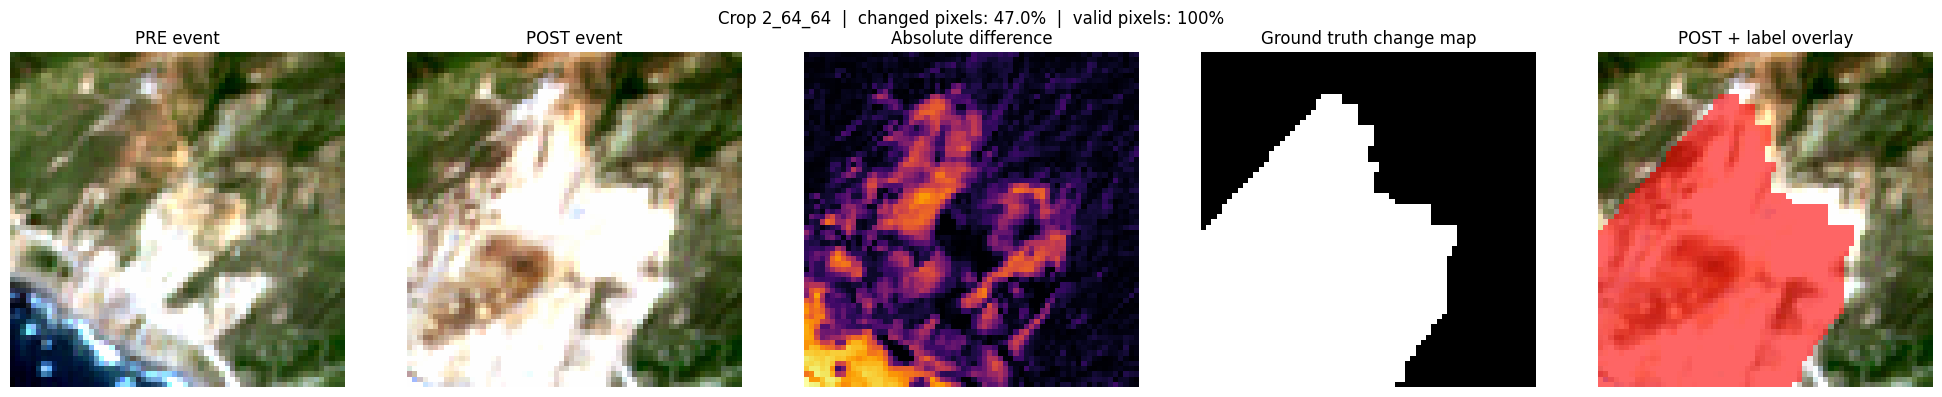

In [ ]:
# @title 1.6 Visualise a processed crop (PRE / POST / difference / label)
import matplotlib.pyplot as plt

RGB_IDX = [3, 2, 1]   # B4 (red), B3 (green), B2 (blue) -> 0-based indices

def to_rgb(arr):
    """arr: (13, H, W) -> stretched (H, W, 3) image for display."""
    rgb = np.moveaxis(arr[RGB_IDX], 0, -1)
    lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

if len(crop_df) > 0:
    # Pick the crop with the most changed pixels so the label is visible
    sample = crop_df.sort_values("changed_frac", ascending=False).iloc[0]

    data  = np.load(sample["path"])
    pre   = data["pre"].astype(np.float32)      # (13, 64, 64)
    post  = data["post"].astype(np.float32)     # (13, 64, 64)
    y     = data["label"].astype(np.uint8)      # (64, 64)
    valid = data["valid"].astype(bool)          # (64, 64)

    # Absolute difference (summed over RGB bands, shown as heatmap)
    diff = np.abs(post - pre)
    diff_map = diff[RGB_IDX].mean(axis=0)

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    axes[0].imshow(to_rgb(pre))
    axes[0].set_title("PRE event")

    axes[1].imshow(to_rgb(post))
    axes[1].set_title("POST event")

    axes[2].imshow(diff_map, cmap="inferno")
    axes[2].set_title("Absolute difference")

    axes[3].imshow(y, cmap="gray", vmin=0, vmax=1)
    axes[3].set_title("Ground truth change map")

    axes[4].imshow(to_rgb(post))
    axes[4].imshow(np.ma.masked_where(y == 0, y), cmap="autumn", alpha=0.6)
    axes[4].set_title("POST + label overlay")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Crop {sample['crop_id']}  |  changed pixels: {100*y.mean():.1f}%  |  "
        f"valid pixels: {100*valid.mean():.0f}%"
    )
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR + "/sample_visualisation.png", dpi=200)
    plt.show()
else:
    print("No crops available for visualisation.")


### 1.7 Grouped 4-fold split (by image pair)
`GroupKFold` on the pair ID guarantees that crops of one pair never appear in both training and validation. The assertion in the cell checks it. Section 5.2 additionally groups by **event**.

In [ ]:
# @title 1.7 Grouped 4-fold split by image pair (no pair in both train and validation)
from sklearn.model_selection import GroupKFold

if crop_df.empty:
    raise ValueError("No crops generated. Check preprocessing.")

n_pairs = crop_df["pair_id"].nunique()

if n_pairs < 4:
    raise ValueError(
        f"Only {n_pairs} labelled pairs produced crops. "
        "Four-fold validation requires at least four pairs."
    )

gkf = GroupKFold(n_splits=4)

fold_records = []

X_dummy = np.zeros(len(crop_df))

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(
        X_dummy,
        groups=crop_df["pair_id"]
    ),
    start=1
):

    train_data = crop_df.iloc[train_idx]
    val_data = crop_df.iloc[val_idx]

    train_groups = set(train_data["pair_id"])
    val_groups = set(val_data["pair_id"])

    # Confirm there is no pair leakage
    assert train_groups.isdisjoint(val_groups)

    for _, item in train_data.iterrows():
        fold_records.append({
            "fold": fold,
            "crop_id": item["crop_id"],
            "pair_id": item["pair_id"],
            "role": "TRAIN"
        })

    for _, item in val_data.iterrows():
        fold_records.append({
            "fold": fold,
            "crop_id": item["crop_id"],
            "pair_id": item["pair_id"],
            "role": "VALIDATION"
        })

    print(f"\nFOLD {fold}")
    print("Training pairs:", len(train_groups))
    print("Validation pairs:", len(val_groups))
    print("Training crops:", len(train_data))
    print("Validation crops:", len(val_data))
    print("Pair leakage:", len(train_groups & val_groups))

fold_df = pd.DataFrame(fold_records)

fold_df.to_csv(
    OUTPUT_DIR + "/four_fold_manifest.csv",
    index=False
)

print("\nFour-fold cross-validation manifest created!")
display(fold_df.head(20))



FOLD 1
Training pairs: 12
Validation pairs: 4
Training crops: 81
Validation crops: 28
Pair leakage: 0

FOLD 2
Training pairs: 12
Validation pairs: 4
Training crops: 82
Validation crops: 27
Pair leakage: 0

FOLD 3
Training pairs: 12
Validation pairs: 4
Training crops: 82
Validation crops: 27
Pair leakage: 0

FOLD 4
Training pairs: 12
Validation pairs: 4
Training crops: 82
Validation crops: 27
Pair leakage: 0

Four-fold cross-validation manifest created!


,fold,crop_id,pair_id,role
0,1,108_0_0,108,TRAIN
1,1,108_0_64,108,TRAIN
2,1,108_64_0,108,TRAIN
3,1,108_64_64,108,TRAIN
4,1,108_128_0,108,TRAIN
5,1,108_128_64,108,TRAIN
6,1,121_0_0,121,TRAIN
7,1,121_0_64,121,TRAIN
8,1,121_64_0,121,TRAIN
9,1,121_64_64,121,TRAIN


### 1.8 Event catalogue: country, trigger, time gap, South Asia
The v2.0 zip does not contain the event CSV, so it is downloaded from the v1 Zenodo record. The catalogue has no country or trigger column: countries are derived from the coordinates, and the `source` and `category` columns (inventory and landslide type) are tabulated in place of triggers.

In [ ]:
# @title 1.8a Event catalogue: events by country, source, type, time gap, South Asia
import os, sys, hashlib, subprocess, requests
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "reverse_geocoder", "pycountry"], check=False)

CSV_URL = "https://zenodo.org/records/10800338/files/landslide_inventory.csv?download=1"
CSV_PATH = BASE_DIR + "/landslide_inventory.csv"
CSV_MD5 = "bdf2a81961832b74bf07829db9e9be2e"

# ---- 1) Download and verify ----
if not os.path.exists(CSV_PATH):
    r = requests.get(CSV_URL, timeout=60)
    r.raise_for_status()
    with open(CSV_PATH, "wb") as f:
        f.write(r.content)
md5 = hashlib.md5(open(CSV_PATH, "rb").read()).hexdigest()
print("MD5 ok:", md5 == CSV_MD5)

# ---- 2) Parse ----
inv = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
for c in ["event_date", "pre1", "pre2", "post1"]:
    inv[c] = pd.to_datetime(inv[c], errors="coerce")

inv["pre_post_gap_d"] = (inv["post1"] - inv["pre2"]).dt.days      # nearest pre image to post image
inv["event_to_post_d"] = (inv["post1"] - inv["event_date"]).dt.days
inv["pre_to_event_d"] = (inv["event_date"] - inv["pre2"]).dt.days
inv["date_issue"] = ((inv["pre2"] > inv["event_date"]) |
                     (inv["post1"] < inv["event_date"]) |
                     (inv["pre1"] > inv["pre2"]))
for c in ["pre_post_gap_d", "event_to_post_d", "pre_to_event_d"]:
    inv.loc[inv["date_issue"], c] = np.nan                         # do not use rows with impossible dates

print("Events in catalogue:", len(inv))
print("Rows with impossible date order (excluded from gap stats):", int(inv["date_issue"].sum()))
if inv["date_issue"].any():
    display(inv.loc[inv["date_issue"], ["event_date", "source", "latitude", "longitude",
                                        "pre1", "pre2", "post1"]])

# ---- 3) Country from coordinates (offline reverse geocoder) ----
SOUTH_ASIA = {"AF", "BD", "BT", "IN", "LK", "MV", "NP", "PK"}
try:
    import reverse_geocoder as rg
    import pycountry
    res = rg.search(list(zip(inv["latitude"], inv["longitude"])), mode=1)
    inv["cc"] = [r["cc"] for r in res]

    def cname(cc):
        c = pycountry.countries.get(alpha_2=cc)
        return c.name if c else cc
    inv["country"] = inv["cc"].map(cname)
except Exception as e:
    print("Reverse geocoder unavailable, using a bounding box for South Asia only:", e)
    inv["cc"] = np.where(inv["latitude"].between(5, 37) & inv["longitude"].between(60, 98), "IN", "??")
    inv["country"] = inv["cc"]

inv["south_asia"] = inv["cc"].isin(SOUTH_ASIA)

# ---- 4) Tables ----
print("\nEVENTS BY COUNTRY")
display(inv["country"].value_counts().rename("n_events").to_frame())

print("\nEVENTS BY SOURCE INVENTORY")
display(inv["source"].value_counts().rename("n_events").to_frame())

print("\nEVENTS BY LANDSLIDE TYPE (category, not trigger)")
display(inv["category"].value_counts().rename("n_events").to_frame())

print("\nCOUNTRY x SOURCE")
display(pd.crosstab(inv["country"], inv["source"]))

print("\nTIME GAPS (days)")
display(inv[["pre_post_gap_d", "pre_to_event_d", "event_to_post_d"]].describe().round(1))

print("\nEvents with pre-to-post gap > 365 days:",
      int((inv["pre_post_gap_d"] > 365).sum()))

print("\nSOUTH ASIA EVENTS:", int(inv["south_asia"].sum()), "of", len(inv))
display(inv.loc[inv["south_asia"], ["event_date", "country", "source", "category",
                                    "latitude", "longitude", "pre_post_gap_d",
                                    "event_to_post_d"]]
        .sort_values("event_date").reset_index(drop=True))


MD5 ok: True
Events in catalogue: 174
Rows with impossible date order (excluded from gap stats): 3


,event_date,source,latitude,longitude,pre1,pre2,post1
96,2020-08-12,IFFI,46.317522,9.795859,2020-07-05,2020-08-19,2020-09-13
147,2018-09-19,Nepal,28.472959,83.611644,2018-05-11,2018-07-20,2018-09-18
159,2023-02-06,Tukey,36.607280,36.359490,2022-10-02,2023-11-06,2023-03-31


Loading formatted geocoded file...

EVENTS BY COUNTRY


,n_events
country,
Italy,66
Nepal,23
India,14
Türkiye,13
United States,11
Ireland,8
Canada,6
Colombia,4
Viet Nam,4



EVENTS BY SOURCE INVENTORY


,n_events
source,
IFFI,62
GLC,59
Nepal,23
Tukey,13
News_manual,7
Ireland,7
UT,2
EMS,1


... (4 outputs left out)


TIME GAPS (days)


,pre_post_gap_d,pre_to_event_d,event_to_post_d
count,171.0,171.0,171.0
mean,180.7,108.0,72.7
std,138.2,103.6,80.8
min,5.0,1.0,0.0
25%,37.5,16.0,14.0
50%,155.0,78.0,40.0
75%,340.0,167.0,108.0
max,415.0,337.0,315.0



Events with pre-to-post gap > 365 days: 11

SOUTH ASIA EVENTS: 39 of 174


,event_date,country,source,category,latitude,longitude,pre_post_gap_d,event_to_post_d
0,2017-05-26,Sri Lanka,GLC,landslide,6.514224,80.169071,135.0,50.0
1,2017-06-30,India,GLC,landslide,27.047686,93.618996,260.0,128.0
2,2017-07-06,India,GLC,landslide,25.812330,91.881410,185.0,120.0
3,2017-07-06,India,GLC,landslide,27.033383,88.273827,255.0,103.0
4,2017-07-11,India,GLC,landslide,27.209384,93.615393,390.0,217.0
5,2017-08-13,India,GLC,debris_flow,31.914229,76.892987,55.0,30.0
6,2018-05-03,Sri Lanka,GLC,debris_flow,6.765405,80.868156,80.0,40.0
7,2018-05-12,India,GLC,landslide,26.079100,94.713200,335.0,192.0
8,2018-06-11,Nepal,Nepal,landslide,28.341554,83.898240,130.0,99.0
9,2018-07-09,Nepal,Nepal,landslide,28.399683,83.965121,130.0,71.0


#### 1.8b Pair locations from the rasters
Each pair's centre coordinates come from its GeoTIFF. The next step uses them to match pairs to catalogue events.

In [ ]:
# @title 1.8b Pair centre coordinates from raster metadata
import rasterio
from rasterio.warp import transform as warp_transform
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

rows, tag_examples = [], {}

for _, r in tqdm(pair_df.iterrows(), total=len(pair_df)):
    with rasterio.open(r["pre"]) as pre_src, rasterio.open(r["post"]) as post_src:
        b = pre_src.bounds
        cx, cy = (b.left + b.right) / 2, (b.bottom + b.top) / 2
        lon, lat = warp_transform(pre_src.crs, "EPSG:4326", [cx], [cy])
        epsg = pre_src.crs.to_epsg()
        area_km2 = (pre_src.width * abs(pre_src.res[0]) *
                    pre_src.height * abs(pre_src.res[1])) / 1e6
        # Keep any metadata tags that might hold dates
        tags = {**pre_src.tags(), **post_src.tags()}
        if tags and not tag_examples:
            tag_examples = tags
    zone = (epsg % 100) if epsg and 32601 <= epsg <= 32760 else np.nan
    hemi = "N" if epsg and 32601 <= epsg <= 32660 else "S"
    rows.append({"pair_id": str(r["pair_id"]), "split": r["split"],
                 "lat": lat[0], "lon": lon[0], "epsg": epsg,
                 "utm_zone": f"{int(zone)}{hemi}" if zone == zone else None,
                 "area_km2": area_km2})

events_df = pd.DataFrame(rows)

# Rough South Asia box: lat 5-37, lon 60-98 (covers Nepal, India, Pakistan, Sri Lanka, Bangladesh, Bhutan)
events_df["south_asia"] = events_df["lat"].between(5, 37) & events_df["lon"].between(60, 98)
events_df["labelled"] = events_df["pair_id"].isin(pair_stats_df["pair_id"].astype(str))

print("Pairs:", len(events_df))
print("South Asia pairs:", int(events_df["south_asia"].sum()),
      "| labelled South Asia pairs:", int((events_df["south_asia"] & events_df["labelled"]).sum()))

print("\nPAIRS PER UTM ZONE")
display(events_df.groupby("utm_zone").size().sort_values(ascending=False).rename("n_pairs").to_frame())

print("\nSOUTH ASIA PAIRS")
display(events_df[events_df["south_asia"]][["pair_id", "split", "lat", "lon", "utm_zone", "labelled"]].round(3))

print("\nMETADATA TAGS FOUND IN RASTERS (look for dates here):")
print(tag_examples if tag_examples else "None - acquisition dates are not stored in the files.")

events_df.to_csv(OUTPUT_DIR + "/event_summary_from_rasters.csv", index=False)


  0%|          | 0/173 [00:00<?, ?it/s]

Pairs: 173
South Asia pairs: 39 | labelled South Asia pairs: 3

PAIRS PER UTM ZONE


,n_pairs
utm_zone,
32N,58
44N,18
29N,10
36N,10
43N,10
33N,9
10N,9
45N,8
17N,5



SOUTH ASIA PAIRS


,pair_id,split,lat,lon,utm_zone,labelled
0,0,TRAIN,31.914,76.893,43N,False
5,102,TRAIN,28.342,83.898,44N,False
6,103,TRAIN,28.400,83.965,44N,False
7,104,TRAIN,28.222,84.488,45N,False
8,105,TRAIN,28.490,83.526,44N,False
9,106,TRAIN,28.420,83.538,44N,False
10,107,TRAIN,28.573,83.437,44N,False
11,109,TRAIN,28.415,83.486,44N,False
13,110,TRAIN,28.622,83.640,44N,False
14,111,TRAIN,28.233,84.320,45N,False



METADATA TAGS FOUND IN RASTERS (look for dates here):
{'AREA_OR_POINT': 'Area'}


#### 1.8c Matching pairs to events
Pair IDs do not follow the CSV row order, so each pair is matched to its event by nearest coordinates.

In [ ]:
# @title 1.8c Match catalogue events to image pairs (by coordinates)
import numpy as np
import pandas as pd

# ---- Match catalogue events to image pairs by nearest coordinates (pair ids do not follow row order) ----
d = np.hypot(events_df["lat"].values[:, None] - inv["latitude"].values[None, :],
             events_df["lon"].values[:, None] - inv["longitude"].values[None, :])
events_df["inv_idx"] = d.argmin(axis=1)
events_df["match_deg"] = d.min(axis=1)
print("\nPairs matched within 0.05 deg:", int((events_df["match_deg"] < 0.05).sum()), "of", len(events_df))
print("Largest match distance (deg):", round(float(events_df["match_deg"].max()), 4))

m = events_df.join(inv.drop(columns=["latitude", "longitude"]), on="inv_idx", rsuffix="_inv")
m = m[m["match_deg"] < 0.05].copy()



Pairs matched within 0.05 deg: 173 of 173
Largest match distance (deg): 0.0001


### 1.9 Preprocessing summary and change features
`build_features` defines the change features asked for in the brief: PRE and POST bands (concatenated), absolute difference, and dNDVI / dBSI. The main U-Nets in section 3 use the raw PRE+POST bands. Section 6.1 tests the full 41-channel feature set.

In [ ]:
# @title 1.9 Preprocessing summary, change-feature builder and report
import numpy as np
import pandas as pd

# ---- Derived change features (computed on the fly from a crop) ----
B2, B4, B8, B11 = 1, 3, 7, 11      # 0-based band indices

def _ndvi(a):
    return (a[B8] - a[B4]) / (a[B8] + a[B4] + 1e-6)

def _bsi(a):
    num = (a[B11] + a[B4]) - (a[B8] + a[B2])
    den = (a[B11] + a[B4]) + (a[B8] + a[B2])
    return num / (den + 1e-6)

def build_features(pre, post):
    """pre, post: (13, H, W) -> (41, H, W) = PRE 13 + POST 13 + |diff| 13 + dNDVI + dBSI"""
    absdiff = np.abs(post - pre)
    dndvi = (_ndvi(post) - _ndvi(pre))[None]
    dbsi = (_bsi(post) - _bsi(pre))[None]
    return np.concatenate([pre, post, absdiff, dndvi, dbsi], axis=0)

# ---- Inspect one crop to get the real channel counts ----
first = np.load(crop_df.iloc[0]["path"])
n_raw = first["pre"].shape[0] + first["post"].shape[0]
n_feat = build_features(first["pre"].astype(np.float32),
                        first["post"].astype(np.float32)).shape[0]

n_pos_crops = int((crop_df["changed_frac"] > 0).sum())
n_pos_pairs = int((pair_stats_df["changed_pct"] > 0).sum())

print("=" * 55)
print("GLAD4CD LANDSLIDE CHANGE DETECTION")
print("PREPROCESSING SUMMARY")
print("=" * 55)

print("Total matched image pairs:", len(pair_df))
print("Labelled pairs:", len(labelled_pairs))
print("Excluded pairs:", len(excluded_df))
print("Processed labelled pairs:", len(pair_stats_df))
print("Total 64x64 crops:", len(crop_df))
print("Crops containing landslide pixels:", n_pos_crops)
print("Raw channels per crop (PRE+POST):", n_raw)
print("Channels after feature building:", n_feat)

print("\nEXCLUDED PAIRS")
if len(excluded_df):
    display(excluded_df)
else:
    print("None")

print("\nCHANGE PIXEL STATISTICS (per pair)")
display(pair_stats_df[["changed_pct", "valid_pct", "n_crops"]].describe().round(2))

print("\nPER-PAIR DETAILS")
display(pair_stats_df.round(2))

print("\nCROPS PER PAIR")
display(crop_df.groupby("pair_id").size().reset_index(name="number_of_crops"))

print("\nCROSS-VALIDATION")
print(fold_df.groupby(["fold", "role"]).size())
print("\nPairs per validation fold:")
print(fold_df[fold_df["role"] == "VALIDATION"].groupby("fold")["pair_id"].nunique())

# ---- Notes for the report ----
if len(excluded_df):
    excl_note = "; ".join(
        f"pair {r.pair_id} ({r.reason})" for r in excluded_df.itertuples()
    )
    excl_note = f"Excluded from all analysis: {excl_note}."
else:
    excl_note = "No pairs were excluded."

report = f"""
GLAD4CD PREPROCESSING REPORT

Total matched pairs: {len(pair_df)}
Labelled pairs: {len(labelled_pairs)}
Excluded pairs: {len(excluded_df)}
Processed labelled pairs: {len(pair_stats_df)}
64x64 crops generated: {len(crop_df)} (stride {STRIDE}, min valid fraction {MIN_VALID_FRACTION})
Crops with landslide pixels: {n_pos_crops}
Mean changed pixels per pair: {pair_stats_df['changed_pct'].mean():.2f}%
Number of validation folds: 4 (GroupKFold by pair, no pair leakage)

Preprocessing performed:
1. Dataset download and MD5 verification.
2. PRE and POST pair matching.
3. GeoTIFF quality checks (size, CRS, transform, bands).
4. Misaligned pairs (offset > {MAX_SHIFT_PX:.0f} px) excluded.
5. 2048x2048 PNG labels resized to image size (nearest neighbour).
6. No-data masking (non-finite or all-zero pixels in either date).
7. Joint per-band percentile normalisation of PRE and POST.
8. 64x64 cropping and changed-pixel percentage per pair.
9. Pair-grouped four-fold cross-validation.
10. Change features built at load time: concatenated bands, absolute
    difference, dNDVI and dBSI ({n_feat} channels).

Notes and limitations:
- Cloud masking was NOT applied: the GeoTIFFs have no cloud band.
- {excl_note}
- Labels were resized from 2048x2048 to the image grid, which may blur
  thin landslide boundaries slightly.
- NDVI/BSI in the crops come from percentile-normalised bands, not raw
  reflectance. The baselines (section 2.1) use raw reflectance.
"""

with open(OUTPUT_DIR + "/preprocessing_report.txt", "w") as f:
    f.write(report)

print(report)


GLAD4CD LANDSLIDE CHANGE DETECTION
PREPROCESSING SUMMARY
Total matched image pairs: 173
Labelled pairs: 17
Excluded pairs: 1
Processed labelled pairs: 16
Total 64x64 crops: 109
Crops containing landslide pixels: 37
Raw channels per crop (PRE+POST): 26
Channels after feature building: 41

EXCLUDED PAIRS


,pair_id,reason,transform_shift_px
0,140,misregistered by 1461 px,1461.43



CHANGE PIXEL STATISTICS (per pair)


,changed_pct,valid_pct,n_crops
count,16.00,16.0,16.00
mean,1.97,100.0,6.81
std,2.07,0.0,1.60
min,0.14,100.0,4.00
25%,0.39,100.0,6.00
50%,1.25,100.0,6.00
75%,2.65,100.0,9.00
max,6.83,100.0,9.00



PER-PAIR DETAILS


,pair_id,height,width,changed_pct,valid_pct,transform_shift_px,n_crops
0,108,211,173,0.41,100.0,0.0,6
1,121,214,175,0.33,100.0,0.0,6
2,125,192,157,2.71,100.0,0.0,6
3,128,191,157,1.67,100.0,0.0,4
4,135,236,193,0.14,100.0,0.0,9
5,155,239,195,6.83,100.0,0.0,9
6,158,206,169,0.23,100.0,0.0,6
7,164,228,187,4.21,100.0,0.0,6
8,171,226,185,2.44,100.0,0.0,6
9,173,245,201,2.63,100.0,0.0,9



CROPS PER PAIR


,pair_id,number_of_crops
0,108,6
1,121,6
2,125,6
3,128,4
4,135,9
5,155,9
6,158,6
7,164,6
8,171,6
9,173,9



CROSS-VALIDATION
fold  role      
1     TRAIN         81
      VALIDATION    28
2     TRAIN         82
      VALIDATION    27
3     TRAIN         82
      VALIDATION    27
4     TRAIN         82
      VALIDATION    27
dtype: int64

Pairs per validation fold:
fold
1    4
2    4
3    4
4    4
Name: pair_id, dtype: int64

GLAD4CD PREPROCESSING REPORT

Total matched pairs: 173
Labelled pairs: 17
Excluded pairs: 1
Processed labelled pairs: 16
64x64 crops generated: 109 (stride 64, min valid fraction 0.8)
Crops with landslide pixels: 37
Mean changed pixels per pair: 1.97%
Number of validation folds: 4 (GroupKFold by pair, no pair leakage)

Preprocessing performed:
1. Dataset download and MD5 verification.
2. PRE and POST pair matching.
3. GeoTIFF quality checks (size, CRS, transform, bands).
4. Misaligned pairs (offset > 1 px) excluded.
5. 2048x2048 PNG labels resized to image size (nearest neighbour).
6. No-data masking (non-finite or all-zero pixels in either date).
7. Joint per-band perc

## 2. Unsupervised baselines
*Brief — Coding task 1.* NDVI differencing and change-vector analysis (CVA), each with an Otsu threshold, scored per pair on the 16 aligned labelled scenes (IoU and F1).

In [ ]:
# @title 2.1 NDVI differencing and CVA baselines with Otsu thresholding
from skimage.filters import threshold_otsu

B2, B3, B4, B8, B11, B12 = 1, 2, 3, 7, 11, 12   # 0-based band indices
CVA_BANDS = [B2, B3, B4, B8, B11, B12]

def iou_f1(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    return tp / (tp + fp + fn + 1e-9), 2 * tp / (2 * tp + fp + fn + 1e-9)

def ndvi(a):
    return (a[B8] - a[B4]) / (a[B8] + a[B4] + 1e-6)

valid_ids = pair_stats_df.loc[pair_stats_df["transform_shift_px"] <= 1, "pair_id"].astype(str).tolist()
lp = labelled_pairs.assign(pair_id=labelled_pairs["pair_id"].astype(str)).set_index("pair_id")

base_rows = []
for pid in valid_ids:
    pre, _, h, w = read_scene(lp.loc[pid, "pre"])
    post, _, _, _ = read_scene(lp.loc[pid, "post"])
    gt = load_label_resized(lp.loc[pid, "label"], h, w).astype(bool)
    valid = (np.isfinite(pre).all(0) & np.isfinite(post).all(0)
             & (pre.sum(0) != 0) & (post.sum(0) != 0))
    pre, post = np.nan_to_num(pre), np.nan_to_num(post)

    # 1) NDVI differencing: landslides REMOVE vegetation, so use the NDVI drop
    drop = ndvi(pre) - ndvi(post)
    t1 = threshold_otsu(drop[valid])
    pred1 = (drop > t1) & valid

    # 2) Change-vector analysis: magnitude of the spectral change vector
    cva = np.linalg.norm((post - pre)[CVA_BANDS], axis=0)
    t2 = threshold_otsu(cva[valid])
    pred2 = (cva > t2) & valid

    for name, pred in [("NDVI-diff", pred1), ("CVA", pred2)]:
        iou, f1 = iou_f1(pred[valid], gt[valid])
        base_rows.append({"pair_id": pid, "method": name, "IoU": iou, "F1": f1,
                          "pred_pct": 100 * pred.mean(), "gt_pct": 100 * gt.mean()})

baseline_df = pd.DataFrame(base_rows)
print("PER-PAIR RESULTS")
display(baseline_df.pivot(index="pair_id", columns="method", values=["IoU", "F1"]).round(3))

print("\nMEAN ± STD ACROSS PAIRS")
display(baseline_df.groupby("method")[["IoU", "F1"]].agg(["mean", "std"]).round(3))
baseline_df.to_csv(OUTPUT_DIR + "/baseline_results.csv", index=False)


PER-PAIR RESULTS


IoU               F1          
method     CVA NDVI-diff    CVA NDVI-diff
pair_id                                  
108      0.053     0.004  0.101     0.008
121      0.007     0.007  0.013     0.014
125      0.047     0.220  0.089     0.360
128      0.033     0.021  0.063     0.040
135      0.002     0.001  0.004     0.003
155      0.088     0.253  0.162     0.404
158      0.011     0.003  0.021     0.006
164      0.046     0.123  0.087     0.219
171      0.299     0.080  0.460     0.149
173      0.293     0.345  0.453     0.513
2        0.283     0.064  0.441     0.120
36       0.024     0.421  0.047     0.592
41       0.036     0.384  0.070     0.555
42       0.004     0.014  0.008     0.027
61       0.009     0.006  0.019     0.012
75       0.054     0.009  0.103     0.019


MEAN ± STD ACROSS PAIRS


IoU            F1       
            mean    std   mean    std
method                               
CVA        0.081  0.107  0.134  0.163
NDVI-diff  0.122  0.151  0.190  0.220

## 3. Supervised models
*Brief — Coding task 2.* An early-fusion U-Net (PRE and POST stacked, 26 channels) and a Siamese U-Net (shared encoder, absolute feature difference). Both are trained for 15 epochs per fold, with Dice + weighted BCE loss and flip/rotation augmentation. Normalisation statistics come from the training fold only.

In [ ]:
# @title 3.1 Data loading, model definitions and training helpers
import time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

SEED = 42
EPOCHS = 15
BATCH_SIZE = 16
LR = 2e-3
BASE_CH = 16


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


# ---- Load all crops into memory (small: ~109 crops) ----
PRE_l, POST_l, Y_l = [], [], []
for p in crop_df["path"]:
    d = np.load(p)
    PRE_l.append(d["pre"])
    POST_l.append(d["post"])
    Y_l.append(d["label"])

PRE = np.stack(PRE_l).astype(np.float32)     # (N, 13, 64, 64)
POST = np.stack(POST_l).astype(np.float32)   # (N, 13, 64, 64)
Y = np.stack(Y_l).astype(np.float32)         # (N, 64, 64)
crop_idx = {cid: i for i, cid in enumerate(crop_df["crop_id"])}
print("PRE:", PRE.shape, "| POST:", POST.shape, "| Y:", Y.shape)


# ---- Model blocks ----
def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
    )


class Encoder(nn.Module):
    def __init__(self, in_ch, base=BASE_CH):
        super().__init__()
        self.b1 = block(in_ch, base)
        self.b2 = block(base, base * 2)
        self.b3 = block(base * 2, base * 4)
        self.b4 = block(base * 4, base * 8)

    def forward(self, x):
        f1 = self.b1(x)                          # 64x64
        f2 = self.b2(F.max_pool2d(f1, 2))        # 32x32
        f3 = self.b3(F.max_pool2d(f2, 2))        # 16x16
        f4 = self.b4(F.max_pool2d(f3, 2))        # 8x8
        return [f1, f2, f3, f4]


class Decoder(nn.Module):
    def __init__(self, base=BASE_CH):
        super().__init__()
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.d3 = block(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.d2 = block(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.d1 = block(base * 2, base)
        self.out = nn.Conv2d(base, 1, 1)

    def forward(self, f):
        x = self.d3(torch.cat([self.up3(f[3]), f[2]], 1))
        x = self.d2(torch.cat([self.up2(x), f[1]], 1))
        x = self.d1(torch.cat([self.up1(x), f[0]], 1))
        return self.out(x).squeeze(1)            # logits (B, H, W)


class EarlyFusionUNet(nn.Module):
    """PRE and POST stacked along channels (26 input channels)."""
    def __init__(self):
        super().__init__()
        self.enc = Encoder(26)
        self.dec = Decoder()

    def forward(self, pre, post):
        return self.dec(self.enc(torch.cat([pre, post], 1)))


class SiameseUNet(nn.Module):
    """Shared encoder on PRE and POST; |feature difference| goes to the decoder."""
    def __init__(self):
        super().__init__()
        self.enc = Encoder(13)
        self.dec = Decoder()

    def forward(self, pre, post):
        fa, fb = self.enc(pre), self.enc(post)
        return self.dec([torch.abs(a - b) for a, b in zip(fa, fb)])


MODELS = {"EarlyFusion": EarlyFusionUNet, "Siamese": SiameseUNet}


# ---- Training helpers ----
def band_stats(train_idx):
    both = np.concatenate([PRE[train_idx], POST[train_idx]], axis=0)
    mean = both.mean(axis=(0, 2, 3)).reshape(1, -1, 1, 1)
    std = both.std(axis=(0, 2, 3)).reshape(1, -1, 1, 1) + 1e-6
    return mean, std


def augment(pre, post, y):
    """Random flips and 90-degree rotations, applied identically to PRE, POST and label."""
    if random.random() < 0.5:
        pre, post, y = pre.flip(-1), post.flip(-1), y.flip(-1)
    if random.random() < 0.5:
        pre, post, y = pre.flip(-2), post.flip(-2), y.flip(-2)
    k = random.randint(0, 3)
    if k:
        pre = torch.rot90(pre, k, (-2, -1))
        post = torch.rot90(post, k, (-2, -1))
        y = torch.rot90(y, k, (-2, -1))
    return pre, post, y


def loss_fn(logits, y, pos_weight):
    bce = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight)
    p = torch.sigmoid(logits)
    inter = (p * y).sum()
    dice = 1 - (2 * inter + 1) / (p.sum() + y.sum() + 1)
    return bce + dice


def train_one(model_cls, train_idx, mean, std):
    model = model_cls().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

    pre = torch.tensor((PRE[train_idx] - mean) / std)
    post = torch.tensor((POST[train_idx] - mean) / std)
    y = torch.tensor(Y[train_idx])

    pos = float(y.sum())
    neg = float(y.numel() - pos)
    pos_weight = torch.tensor(min(neg / max(pos, 1.0), 10.0), device=device)

    n = len(train_idx)
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(n)
        for s in range(0, n, BATCH_SIZE):
            b = perm[s:s + BATCH_SIZE]
            xb_pre, xb_post, yb = augment(pre[b].to(device), post[b].to(device), y[b].to(device))
            opt.zero_grad()
            loss = loss_fn(model(xb_pre, xb_post), yb, pos_weight)
            loss.backward()
            opt.step()
    return model


@torch.no_grad()
def predict(model, val_idx, mean, std):
    model.eval()
    pre = torch.tensor((PRE[val_idx] - mean) / std).to(device)
    post = torch.tensor((POST[val_idx] - mean) / std).to(device)
    return torch.sigmoid(model(pre, post)).cpu().numpy()


print("Models and helpers defined.")


Device: cuda
PRE: (109, 13, 64, 64) | POST: (109, 13, 64, 64) | Y: (109, 64, 64)
Models and helpers defined.


In [ ]:
# @title 3.2 Pair-grouped 4-fold training (2 models x 4 folds = 8 runs)
set_seed(SEED)

THRESH = 0.5
pred_store = {m: {} for m in MODELS}     # model -> {crop_id: probability map}
pair_rows = []

t_start = time.time()
for model_name, model_cls in MODELS.items():
    for fold in sorted(fold_df["fold"].unique()):
        t0 = time.time()
        fd = fold_df[fold_df["fold"] == fold]
        train_ids = fd.loc[fd["role"] == "TRAIN", "crop_id"].tolist()
        val_ids = fd.loc[fd["role"] == "VALIDATION", "crop_id"].tolist()
        train_idx = np.array([crop_idx[c] for c in train_ids])
        val_idx = np.array([crop_idx[c] for c in val_ids])

        # No pair may appear on both sides
        tr_pairs = set(crop_df.iloc[train_idx]["pair_id"])
        va_pairs = set(crop_df.iloc[val_idx]["pair_id"])
        assert tr_pairs.isdisjoint(va_pairs), "Pair leakage!"

        set_seed(SEED + int(fold))
        mean, std = band_stats(train_idx)          # training-fold statistics only
        model = train_one(model_cls, train_idx, mean, std)
        probs = predict(model, val_idx, mean, std)

        for cid, p in zip(val_ids, probs):
            pred_store[model_name][cid] = p

        # Per-pair metrics: pool TP/FP/FN over that pair's validation crops
        vdf = crop_df.iloc[val_idx].reset_index(drop=True)
        for pid, grp in vdf.groupby("pair_id"):
            ii = grp.index.values
            pred = probs[ii] > THRESH
            gt = Y[val_idx][ii] > 0.5
            tp = (pred & gt).sum()
            fp = (pred & ~gt).sum()
            fn = (~pred & gt).sum()
            iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else np.nan
            f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else np.nan
            pair_rows.append({"model": model_name, "fold": int(fold), "pair_id": str(pid),
                              "IoU": iou, "F1": f1,
                              "gt_pct": 100 * gt.mean(), "pred_pct": 100 * pred.mean()})

        print(f"{model_name:12s} fold {fold}: val pairs={sorted(va_pairs)}  ({time.time() - t0:.0f}s)")

print(f"\nTotal training time: {(time.time() - t_start) / 60:.1f} min")

results_df = pd.DataFrame(pair_rows)
results_df.to_csv(OUTPUT_DIR + "/unet_pair_results.csv", index=False)
display(results_df.pivot(index="pair_id", columns="model", values=["IoU", "F1"]).round(3))


EarlyFusion  fold 1: val pairs=['128', '155', '164', '41']  (10s)
EarlyFusion  fold 2: val pairs=['125', '171', '36', '42']  (1s)
EarlyFusion  fold 3: val pairs=['121', '173', '2', '75']  (1s)
EarlyFusion  fold 4: val pairs=['108', '135', '158', '61']  (1s)
Siamese      fold 1: val pairs=['128', '155', '164', '41']  (2s)
Siamese      fold 2: val pairs=['125', '171', '36', '42']  (2s)
Siamese      fold 3: val pairs=['121', '173', '2', '75']  (2s)
Siamese      fold 4: val pairs=['108', '135', '158', '61']  (2s)

Total training time: 0.4 min


IoU                  F1        
model   EarlyFusion Siamese EarlyFusion Siamese
pair_id                                        
108           0.058   0.025       0.109   0.049
121           0.119   0.000       0.212   0.000
125           0.045   0.176       0.086   0.299
128           0.063   0.151       0.119   0.263
135           0.064   0.008       0.120   0.016
155           0.241   0.335       0.389   0.502
158           0.000   0.010       0.000   0.020
164           0.127   0.125       0.226   0.223
171           0.722   0.311       0.839   0.475
173           0.227   0.290       0.370   0.450
2             0.535   0.399       0.697   0.570
36            0.340   0.496       0.508   0.664
41            0.236   0.349       0.382   0.517
42            0.100   0.019       0.181   0.037
61            0.014   0.045       0.027   0.087
75            0.479   0.172       0.647   0.293

## 4. Results
*Brief — Coding task 4.* Mean ± standard deviation of IoU and F1 across pairs for all four methods, and the best and worst validation pair as before / after / prediction / label panels.

MEAN ± STD ACROSS PAIRS


,Method,n_pairs,IoU,F1
0,"CVA (Otsu, full scene)",16,0.081 ± 0.107,0.134 ± 0.163
1,"NDVI-diff (Otsu, full scene)",16,0.122 ± 0.151,0.190 ± 0.220
2,EarlyFusion U-Net (4-fold grouped CV),16,0.210 ± 0.210,0.307 ± 0.254
3,Siamese U-Net (4-fold grouped CV),16,0.182 ± 0.162,0.279 ± 0.227



IoU PER PAIR, ALL METHODS


,CVA,NDVI-diff,EarlyFusion,Siamese
pair_id,,,,
108,0.053,0.004,0.058,0.025
121,0.007,0.007,0.119,0.000
125,0.047,0.220,0.045,0.176
128,0.033,0.021,0.063,0.151
135,0.002,0.001,0.064,0.008
155,0.088,0.253,0.241,0.335
158,0.011,0.003,0.000,0.010
164,0.046,0.123,0.127,0.125
171,0.299,0.080,0.722,0.311



Best model: EarlyFusion | best pair: 171 | worst pair: 158


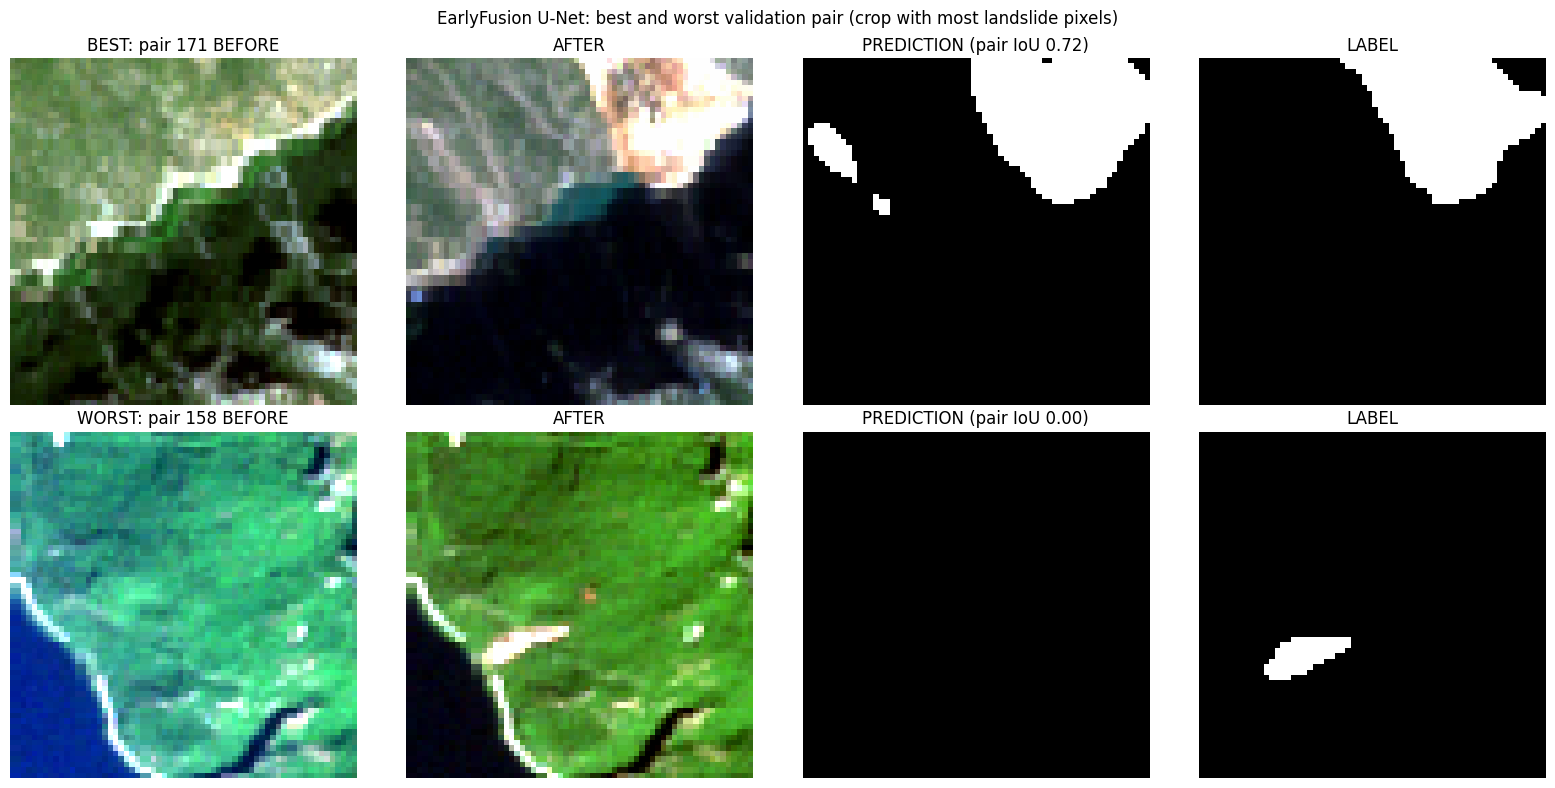

In [ ]:
# @title 4.1 Mean ± std table, per-pair IoU and best/worst pair panels
import matplotlib.pyplot as plt

# ---- Combined mean ± std table ----
summary = []
for name, g in baseline_df.groupby("method"):
    summary.append({"Method": name + " (Otsu, full scene)", "n_pairs": len(g),
                    "IoU": f"{g['IoU'].mean():.3f} ± {g['IoU'].std():.3f}",
                    "F1": f"{g['F1'].mean():.3f} ± {g['F1'].std():.3f}"})
for name, g in results_df.groupby("model"):
    summary.append({"Method": name + " U-Net (4-fold grouped CV)", "n_pairs": g["IoU"].notna().sum(),
                    "IoU": f"{g['IoU'].mean():.3f} ± {g['IoU'].std():.3f}",
                    "F1": f"{g['F1'].mean():.3f} ± {g['F1'].std():.3f}"})
summary_df = pd.DataFrame(summary)
print("MEAN ± STD ACROSS PAIRS")
display(summary_df)
summary_df.to_csv(OUTPUT_DIR + "/final_summary.csv", index=False)

# ---- Per-pair comparison across all four methods ----
base_wide = baseline_df.pivot(index="pair_id", columns="method", values="IoU")
unet_wide = results_df.pivot(index="pair_id", columns="model", values="IoU")
all_wide = base_wide.join(unet_wide, how="outer").round(3)
print("\nIoU PER PAIR, ALL METHODS")
display(all_wide)

# ---- Best / worst pair for the better U-Net ----
best_model = results_df.groupby("model")["IoU"].mean().idxmax()
rd = results_df[results_df["model"] == best_model].dropna(subset=["IoU"])
best_pid = rd.loc[rd["IoU"].idxmax(), "pair_id"]
worst_pid = rd.loc[rd["IoU"].idxmin(), "pair_id"]
print(f"\nBest model: {best_model} | best pair: {best_pid} | worst pair: {worst_pid}")

RGB_IDX = [3, 2, 1]   # B4, B3, B2

def to_rgb(arr):
    rgb = np.moveaxis(arr[RGB_IDX], 0, -1)
    lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

def row_for(pid, ax_row, tag):
    grp = crop_df[crop_df["pair_id"] == pid].sort_values("changed_frac", ascending=False)
    cid = grp.iloc[0]["crop_id"]
    i = crop_idx[cid]
    prob = pred_store[best_model][cid]
    m = results_df[(results_df["model"] == best_model) & (results_df["pair_id"] == pid)].iloc[0]
    ax_row[0].imshow(to_rgb(PRE[i]));  ax_row[0].set_title(f"{tag}: pair {pid} BEFORE")
    ax_row[1].imshow(to_rgb(POST[i])); ax_row[1].set_title("AFTER")
    ax_row[2].imshow(prob > THRESH, cmap="gray", vmin=0, vmax=1)
    ax_row[2].set_title(f"PREDICTION (pair IoU {m['IoU']:.2f})")
    ax_row[3].imshow(Y[i], cmap="gray", vmin=0, vmax=1); ax_row[3].set_title("LABEL")
    for a in ax_row:
        a.axis("off")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
row_for(best_pid, axes[0], "BEST")
row_for(worst_pid, axes[1], "WORST")
plt.suptitle(f"{best_model} U-Net: best and worst validation pair (crop with most landslide pixels)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/best_worst_panels.png", dpi=200)
plt.show()


## 5. Validation design
Why validation must be grouped, and how much grouping matters.

### 5.1 Random crop split vs pair-grouped split
The random split lets crops of the same scene sit on both sides of the split.

In [ ]:
# @title 5.1 Random-crop split vs pair-grouped split (EarlyFusion U-Net)
from sklearn.model_selection import KFold

MODEL_NAME = "EarlyFusion"
N = len(crop_df)
crop_df = crop_df.reset_index(drop=True)

# ---- 1) Random crop-level 4-fold (crops from one pair CAN be on both sides) ----
kf = KFold(n_splits=4, shuffle=True, random_state=SEED)
rand_probs = np.zeros_like(Y)
t0 = time.time()
for fold, (tr, va) in enumerate(kf.split(np.arange(N)), start=1):
    leaked = set(crop_df.iloc[tr]["pair_id"]) & set(crop_df.iloc[va]["pair_id"])
    set_seed(SEED + fold)
    mean, std = band_stats(tr)
    model = train_one(MODELS[MODEL_NAME], tr, mean, std)
    rand_probs[va] = predict(model, va, mean, std)
    print(f"Random fold {fold}: train crops={len(tr)}, val crops={len(va)}, "
          f"pairs on BOTH sides={len(leaked)}")
print(f"Random-split time: {(time.time() - t0) / 60:.1f} min")

# ---- 2) Grouped predictions from section 3.2 ----
grp_probs = np.stack([pred_store[MODEL_NAME][c] for c in crop_df["crop_id"]])


def iou_f1_counts(pred, gt):
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else np.nan
    return iou, f1


def per_pair_metrics(probs):
    rows = []
    for pid, ii in crop_df.groupby("pair_id").indices.items():
        iou, f1 = iou_f1_counts(probs[ii] > THRESH, Y[ii] > 0.5)
        rows.append({"pair_id": str(pid), "IoU": iou, "F1": f1})
    return pd.DataFrame(rows)


rand_pp = per_pair_metrics(rand_probs)
grp_pp = per_pair_metrics(grp_probs)

# Pooled over all crops (one number per strategy)
rand_pool = iou_f1_counts(rand_probs > THRESH, Y > 0.5)
grp_pool = iou_f1_counts(grp_probs > THRESH, Y > 0.5)

comp = pd.DataFrame({
    "Split": ["Random crop split", "Grouped by pair"],
    "Mean IoU per pair": [rand_pp["IoU"].mean(), grp_pp["IoU"].mean()],
    "Std IoU per pair": [rand_pp["IoU"].std(), grp_pp["IoU"].std()],
    "Mean F1 per pair": [rand_pp["F1"].mean(), grp_pp["F1"].mean()],
    "Pooled IoU (all crops)": [rand_pool[0], grp_pool[0]],
    "Pooled F1 (all crops)": [rand_pool[1], grp_pool[1]],
}).round(3)

print("\nRANDOM vs GROUPED SPLIT")
display(comp)
gap = comp.loc[0, "Mean IoU per pair"] - comp.loc[1, "Mean IoU per pair"]
print(f"Gap in mean per-pair IoU (random - grouped): {gap:+.3f}")

both = rand_pp.merge(grp_pp, on="pair_id", suffixes=("_random", "_grouped")).round(3)
print("\nPER-PAIR IoU")
display(both[["pair_id", "IoU_random", "IoU_grouped"]])

comp.to_csv(OUTPUT_DIR + "/random_vs_grouped.csv", index=False)


Random fold 1: train crops=81, val crops=28, pairs on BOTH sides=15
Random fold 2: train crops=82, val crops=27, pairs on BOTH sides=13
Random fold 3: train crops=82, val crops=27, pairs on BOTH sides=14
Random fold 4: train crops=82, val crops=27, pairs on BOTH sides=14
Random-split time: 0.1 min

RANDOM vs GROUPED SPLIT


,Split,Mean IoU per pair,Std IoU per pair,Mean F1 per pair,Pooled IoU (all crops),Pooled F1 (all crops)
0,Random crop split,0.24,0.174,0.359,0.252,0.403
1,Grouped by pair,0.21,0.210,0.307,0.138,0.243


Gap in mean per-pair IoU (random - grouped): +0.030

PER-PAIR IoU


,pair_id,IoU_random,IoU_grouped
0,108,0.057,0.058
1,121,0.094,0.119
2,125,0.160,0.045
3,128,0.091,0.063
4,135,0.047,0.064
5,155,0.274,0.241
6,158,0.260,0.000
7,164,0.159,0.127
8,171,0.559,0.722
9,173,0.258,0.227


### 5.2 Event-level leakage check and event-grouped CV
Several labelled pairs come from the same event (same country and month). The check shows whether the pair-grouped folds still put a sibling pair of an event in training, then re-runs both U-Nets with event-grouped folds.

In [ ]:
# @title 5.2 Event-level leakage check and event-grouped 4-fold CV
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

# ---- 1) Event groups: same country AND same month ----
ev = m.copy()
ev["pair_id"] = ev["pair_id"].astype(str)
ev["event_group"] = ev["country"] + "_" + ev["event_date"].dt.to_period("M").astype(str)
pid2grp = ev.set_index("pair_id")["event_group"].to_dict()

crop_df = crop_df.reset_index(drop=True)
crop_df["event_group"] = crop_df["pair_id"].astype(str).map(pid2grp)

n_pairs_per_event = crop_df.groupby("event_group")["pair_id"].nunique()
shared = n_pairs_per_event[n_pairs_per_event > 1]
print("Labelled pairs:", crop_df["pair_id"].nunique(),
      "| distinct events:", crop_df["event_group"].nunique())
print("\nEVENTS WITH MORE THAN ONE LABELLED PAIR")
for g in shared.index:
    ids = sorted(crop_df.loc[crop_df["event_group"] == g, "pair_id"].astype(str).unique(), key=int)
    print(f"  {g}: pairs {ids}")

# ---- 2) Do the existing pair-grouped folds (section 1.7) leak events? ----
print("\nEVENT OVERLAP BETWEEN TRAIN AND VALIDATION IN THE PAIR-GROUPED FOLDS")
for fold, fd in fold_df.groupby("fold"):
    tr = set(fd.loc[fd["role"] == "TRAIN", "pair_id"].astype(str).map(pid2grp))
    va = set(fd.loc[fd["role"] == "VALIDATION", "pair_id"].astype(str).map(pid2grp))
    vp = sorted(fd.loc[fd["role"] == "VALIDATION", "pair_id"].astype(str).unique(), key=int)
    both = sorted(tr & va)
    print(f"  Fold {fold}: validation pairs {vp} | events also in training: {both if both else 'none'}")

# ---- 3) Event-grouped 4-fold CV for both U-Nets ----
gkf = GroupKFold(n_splits=4)
rows = []
t0 = time.time()
for model_name, model_cls in MODELS.items():
    for fold, (tr, va) in enumerate(
            gkf.split(np.zeros(len(crop_df)), groups=crop_df["event_group"]), start=1):
        tr_ev = set(crop_df.iloc[tr]["event_group"])
        va_ev = set(crop_df.iloc[va]["event_group"])
        assert tr_ev.isdisjoint(va_ev), "Event leakage!"

        set_seed(SEED + fold)
        mean, std = band_stats(tr)                       # training-fold statistics only
        model = train_one(model_cls, tr, mean, std)
        probs = predict(model, va, mean, std)

        vdf = crop_df.iloc[va].reset_index(drop=True)
        for pid, grp in vdf.groupby("pair_id"):
            ii = grp.index.values
            iou, f1 = iou_f1_counts(probs[ii] > THRESH, Y[va][ii] > 0.5)
            rows.append({"model": model_name, "fold": fold, "pair_id": str(pid),
                         "IoU": iou, "F1": f1})
print(f"\nEvent-grouped training time: {(time.time() - t0) / 60:.1f} min")

evt_df = pd.DataFrame(rows)
evt_df.to_csv(OUTPUT_DIR + "/unet_event_grouped_results.csv", index=False)

# ---- 4) Compare pair-grouped vs event-grouped ----
cmp_rows = []
for name in MODELS:
    a = results_df[results_df["model"] == name]
    b = evt_df[evt_df["model"] == name]
    cmp_rows.append({
        "Model": name,
        "IoU pair-grouped": f"{a['IoU'].mean():.3f} ± {a['IoU'].std():.3f}",
        "IoU event-grouped": f"{b['IoU'].mean():.3f} ± {b['IoU'].std():.3f}",
        "F1 pair-grouped": f"{a['F1'].mean():.3f} ± {a['F1'].std():.3f}",
        "F1 event-grouped": f"{b['F1'].mean():.3f} ± {b['F1'].std():.3f}",
    })
print("\nPAIR-GROUPED vs EVENT-GROUPED (mean ± std across 16 pairs)")
display(pd.DataFrame(cmp_rows))

shared_pairs = sorted(crop_df.loc[crop_df["event_group"].isin(shared.index), "pair_id"]
                      .astype(str).unique(), key=int)
tab = pd.DataFrame({"event_group": pd.Series(pid2grp).reindex(shared_pairs)})
for name in MODELS:
    tab[f"{name} pair-grouped"] = results_df[results_df["model"] == name].set_index("pair_id")["IoU"].reindex(shared_pairs)
    tab[f"{name} event-grouped"] = evt_df[evt_df["model"] == name].set_index("pair_id")["IoU"].reindex(shared_pairs)
print("\nIoU FOR PAIRS THAT SHARE AN EVENT")
display(tab.round(3))


Labelled pairs: 16 | distinct events: 13

EVENTS WITH MORE THAN ONE LABELLED PAIR
  India_2018-08: pairs ['41', '42']
  Ireland_2017-08: pairs ['125', '128']
  Türkiye_2023-02: pairs ['164', '171']

EVENT OVERLAP BETWEEN TRAIN AND VALIDATION IN THE PAIR-GROUPED FOLDS
  Fold 1: validation pairs ['41', '128', '155', '164'] | events also in training: ['India_2018-08', 'Ireland_2017-08', 'Türkiye_2023-02']
  Fold 2: validation pairs ['36', '42', '125', '171'] | events also in training: ['India_2018-08', 'Ireland_2017-08', 'Türkiye_2023-02']
  Fold 3: validation pairs ['2', '75', '121', '173'] | events also in training: none
  Fold 4: validation pairs ['61', '108', '135', '158'] | events also in training: none

Event-grouped training time: 0.2 min

PAIR-GROUPED vs EVENT-GROUPED (mean ± std across 16 pairs)


,Model,IoU pair-grouped,IoU event-grouped,F1 pair-grouped,F1 event-grouped
0,EarlyFusion,0.210 ± 0.210,0.145 ± 0.135,0.307 ± 0.254,0.232 ± 0.196
1,Siamese,0.182 ± 0.162,0.151 ± 0.166,0.279 ± 0.227,0.232 ± 0.231



IoU FOR PAIRS THAT SHARE AN EVENT


,event_group,EarlyFusion pair-grouped,EarlyFusion event-grouped,Siamese pair-grouped,Siamese event-grouped
41,India_2018-08,0.236,0.156,0.349,0.448
42,India_2018-08,0.100,0.088,0.019,0.000
125,Ireland_2017-08,0.045,0.050,0.176,0.068
128,Ireland_2017-08,0.063,0.061,0.151,0.102
164,Türkiye_2023-02,0.127,0.221,0.125,0.058
171,Türkiye_2023-02,0.722,0.397,0.311,0.000


## 6. Ablations and optional self-supervised pre-training
All variants use the same folds, the same budget and 3 seeds per fold; results are averaged over seeds per pair.

### 6.1 Change features and the value of the pre-event image
- **41-channel features** (bands + absolute difference + dNDVI + dBSI) vs raw 26 channels.
- **POST-only** U-Net (single date): shows what the pre-event image adds.

In [ ]:
# @title 6.1 Ablations: change features and POST-only (3 seeds, pair- and event-grouped CV)
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

SEEDS = [42, 43, 44]
V_BASE = "EarlyFusion 26ch (baseline)"
V_FEAT = "EarlyFusion + diff/dNDVI/dBSI (41ch)"
V_POST = "POST-only 13ch"
ABL_VARIANTS = [V_BASE, V_FEAT, V_POST]

# 41 channels: PRE 13 + POST 13 + |diff| 13 + dNDVI + dBSI (build_features is defined in section 1.9)
FEAT = np.stack([build_features(PRE[i], POST[i]) for i in range(len(PRE))]).astype(np.float32)
print("Feature tensor:", FEAT.shape)


class PostOnlyUNet(nn.Module):
    """Single-date model: ignores the PRE image."""
    def __init__(self):
        super().__init__()
        self.enc = Encoder(13)
        self.dec = Decoder()

    def forward(self, pre, post):
        return self.dec(self.enc(post))


class FeatUNet(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.enc = Encoder(in_ch)
        self.dec = Decoder()

    def forward(self, x):
        return self.dec(self.enc(x))


def train_feat(in_ch, tr, mean, std):
    model = FeatUNet(in_ch).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    x = torch.tensor((FEAT[tr] - mean) / std)
    y = torch.tensor(Y[tr])
    pos = float(y.sum())
    neg = float(y.numel() - pos)
    pos_weight = torch.tensor(min(neg / max(pos, 1.0), 10.0), device=device)
    n = len(tr)
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(n)
        for s in range(0, n, BATCH_SIZE):
            b = perm[s:s + BATCH_SIZE]
            xb, _, yb = augment(x[b].to(device), x[b].to(device), y[b].to(device))
            opt.zero_grad()
            loss = loss_fn(model(xb), yb, pos_weight)
            loss.backward()
            opt.step()
    return model


@torch.no_grad()
def predict_feat(model, va, mean, std):
    model.eval()
    x = torch.tensor((FEAT[va] - mean) / std).to(device)
    return torch.sigmoid(model(x)).cpu().numpy()


def run_variant(variant, tr, va):
    if variant == V_BASE:
        mean, std = band_stats(tr)
        return predict(train_one(EarlyFusionUNet, tr, mean, std), va, mean, std)
    if variant == V_POST:
        mean, std = band_stats(tr)
        return predict(train_one(PostOnlyUNet, tr, mean, std), va, mean, std)
    mean = FEAT[tr].mean(axis=(0, 2, 3)).reshape(1, -1, 1, 1)
    std = FEAT[tr].std(axis=(0, 2, 3)).reshape(1, -1, 1, 1) + 1e-6
    return predict_feat(train_feat(FEAT.shape[1], tr, mean, std), va, mean, std)


def get_folds(scheme):
    """Returns [(fold, train_idx, val_idx)] for 'pair-grouped' (section 1.7) or 'event-grouped' (section 5.2)."""
    if scheme == "pair-grouped":
        out = []
        for fold in sorted(fold_df["fold"].unique()):
            fd = fold_df[fold_df["fold"] == fold]
            tr = np.array([crop_idx[c] for c in fd.loc[fd["role"] == "TRAIN", "crop_id"]])
            va = np.array([crop_idx[c] for c in fd.loc[fd["role"] == "VALIDATION", "crop_id"]])
            out.append((int(fold), tr, va))
        return out
    gkf = GroupKFold(n_splits=4)
    return [(i, tr, va) for i, (tr, va) in enumerate(
        gkf.split(np.zeros(len(crop_df)), groups=crop_df["event_group"]), start=1)]


def score_into(rows, probs, va, scheme, variant, seed, fold):
    vdf = crop_df.iloc[va].reset_index(drop=True)
    for pid, grp in vdf.groupby("pair_id"):
        ii = grp.index.values
        iou, f1 = iou_f1_counts(probs[ii] > THRESH, Y[va][ii] > 0.5)
        rows.append({"scheme": scheme, "variant": variant, "seed": int(seed), "fold": int(fold),
                     "pair_id": str(pid), "IoU": iou, "F1": f1})


def summarise(df):
    """Average seeds per pair, then mean ± std across pairs; paired difference vs the baseline."""
    pp = df.groupby(["scheme", "variant", "pair_id"])[["IoU", "F1"]].mean().reset_index()
    summ = pp.groupby(["scheme", "variant"]).agg(
        IoU_mean=("IoU", "mean"), IoU_std=("IoU", "std"),
        F1_mean=("F1", "mean"), F1_std=("F1", "std"),
        n_pairs=("IoU", "count")).round(3)
    display(summ)
    base = pp[pp["variant"] == V_BASE].set_index(["scheme", "pair_id"])["IoU"]
    print("\nPAIRED DIFFERENCE IN IoU vs BASELINE (same pairs, seed-averaged)")
    for scheme in pp["scheme"].unique():
        for v in [x for x in pp["variant"].unique() if x != V_BASE]:
            cur = pp[(pp["scheme"] == scheme) & (pp["variant"] == v)].set_index("pair_id")["IoU"]
            d = (cur - base.loc[scheme].reindex(cur.index)).dropna()
            print(f"  {scheme:13s} {v:40s} mean diff {d.mean():+.3f} | better on {int((d > 0).sum())}/{len(d)} pairs")


abl_rows = []
t0 = time.time()
for scheme in ["pair-grouped", "event-grouped"]:
    for fold, tr, va in get_folds(scheme):
        if scheme == "pair-grouped":
            assert set(crop_df.iloc[tr]["pair_id"]).isdisjoint(set(crop_df.iloc[va]["pair_id"]))
        else:
            assert set(crop_df.iloc[tr]["event_group"]).isdisjoint(set(crop_df.iloc[va]["event_group"]))
        for variant in ABL_VARIANTS:
            for seed in SEEDS:
                set_seed(seed + fold)
                probs = run_variant(variant, tr, va)
                score_into(abl_rows, probs, va, scheme, variant, seed, fold)
    print(f"{scheme} done ({(time.time() - t0) / 60:.1f} min)")

abl_df = pd.DataFrame(abl_rows)
abl_df.to_csv(OUTPUT_DIR + "/ablation_results.csv", index=False)
print("\nABLATIONS: mean ± std across 16 pairs (IoU/F1 averaged over 3 seeds per pair)")
summarise(abl_df)


Feature tensor: (109, 41, 64, 64)
pair-grouped done (20.0 min)
event-grouped done (39.6 min)

ABLATIONS: mean ± std across 16 pairs (IoU/F1 averaged over 3 seeds per pair)


IoU_mean  IoU_std  \
scheme        variant                                                   
event-grouped EarlyFusion + diff/dNDVI/dBSI (41ch)     0.219    0.179   
              EarlyFusion 26ch (baseline)              0.182    0.156   
              POST-only 13ch                           0.088    0.090   
pair-grouped  EarlyFusion + diff/dNDVI/dBSI (41ch)     0.201    0.172   
              EarlyFusion 26ch (baseline)              0.199    0.165   
              POST-only 13ch                           0.141    0.175   

                                                    F1_mean  F1_std  n_pairs  
scheme        variant                                                         
event-grouped EarlyFusion + diff/dNDVI/dBSI (41ch)    0.323   0.232       16  
              EarlyFusion 26ch (baseline)             0.280   0.209       16  
              POST-only 13ch                          0.148   0.141       16  
pair-grouped  EarlyFusion + diff/dNDVI/dBSI (41ch)    0.301   0.217       16  
              EarlyFusion 26ch (baseline)             0.297   0.218       16  
              POST-only 13ch                          0.213   0.223       16


PAIRED DIFFERENCE IN IoU vs BASELINE (same pairs, seed-averaged)
  event-grouped EarlyFusion + diff/dNDVI/dBSI (41ch)     mean diff +0.037 | better on 12/16 pairs
  event-grouped POST-only 13ch                           mean diff -0.094 | better on 5/16 pairs
  pair-grouped  EarlyFusion + diff/dNDVI/dBSI (41ch)     mean diff +0.002 | better on 8/16 pairs
  pair-grouped  POST-only 13ch                           mean diff -0.058 | better on 5/16 pairs


### 6.2 Optional: self-supervised pre-training
*Brief — Coding task 3 (≤ 5 epochs).* A masked autoencoder is trained on the unlabelled TRAIN patches (no labels used), and its encoder initialises the early-fusion U-Net.

In [ ]:
# @title 6.2 Optional: self-supervised pre-training (masked autoencoder, 5 epochs) + fine-tuning
import time
from tqdm.auto import tqdm

AE_EPOCHS = 5
MASK_CELL = 8        # mask 8x8-pixel blocks
MASK_P = 0.4         # fraction of blocks hidden

# ---- 1) Unlabelled TRAIN crops (labels are never used) ----
unl = pair_df[pair_df["split"] == "TRAIN"]
Xu = []
for _, row in tqdm(unl.iterrows(), total=len(unl)):
    try:
        pre, pre_tf, ph, pw = read_scene(row["pre"])
        post, post_tf, qh, qw = read_scene(row["post"])
    except Exception:
        continue
    if (ph, pw) != (qh, qw) or pre.shape[0] != post.shape[0]:
        continue
    shift_px = max(abs(pre_tf.c - post_tf.c), abs(pre_tf.f - post_tf.f)) / abs(pre_tf.a)
    if shift_px > MAX_SHIFT_PX:
        continue
    valid = (np.isfinite(pre).all(0) & np.isfinite(post).all(0)
             & (pre.sum(0) != 0) & (post.sum(0) != 0))
    pre_n, post_n = normalise_pair(np.nan_to_num(pre), np.nan_to_num(post), valid)
    both = np.concatenate([pre_n, post_n], axis=0)
    for y0 in range(0, ph - CROP_SIZE + 1, STRIDE):
        for x0 in range(0, pw - CROP_SIZE + 1, STRIDE):
            sl = (slice(y0, y0 + CROP_SIZE), slice(x0, x0 + CROP_SIZE))
            if valid[sl].mean() >= MIN_VALID_FRACTION:
                Xu.append(both[(slice(None),) + sl].astype(np.float16))
Xu = np.stack(Xu).astype(np.float32)
print("Unlabelled TRAIN crops:", Xu.shape)


# ---- 2) Masked autoencoder: same encoder/decoder blocks, 26 output channels ----
class MAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = Encoder(26)
        self.dec = Decoder()
        self.dec.out = nn.Conv2d(BASE_CH, 26, 1)

    def forward(self, x):
        return self.dec(self.enc(x))       # squeeze(1) in Decoder is a no-op for 26 channels


set_seed(SEED)
mu = Xu.mean(axis=(0, 2, 3)).reshape(1, -1, 1, 1)
sd = Xu.std(axis=(0, 2, 3)).reshape(1, -1, 1, 1) + 1e-6
Xt = torch.tensor((Xu - mu) / sd)

ae = MAE().to(device)
opt = torch.optim.AdamW(ae.parameters(), lr=LR, weight_decay=1e-4)
t0 = time.time()
for ep in range(AE_EPOCHS):
    ae.train()
    perm = torch.randperm(len(Xt))
    tot, nb = 0.0, 0
    for s in range(0, len(Xt), BATCH_SIZE * 2):
        xb = Xt[perm[s:s + BATCH_SIZE * 2]].to(device)
        if random.random() < 0.5:
            xb = xb.flip(-1)
        if random.random() < 0.5:
            xb = xb.flip(-2)
        xb = torch.rot90(xb, random.randint(0, 3), (-2, -1))
        g = CROP_SIZE // MASK_CELL
        mask = (torch.rand(xb.shape[0], 1, g, g, device=device) < MASK_P).float()
        mask = mask.repeat_interleave(MASK_CELL, 2).repeat_interleave(MASK_CELL, 3)
        rec = ae(xb * (1 - mask))
        loss = (((rec - xb) ** 2) * mask).sum() / (mask.sum() * xb.shape[1] + 1e-6)
        opt.zero_grad()
        loss.backward()
        opt.step()
        tot += loss.item()
        nb += 1
    print(f"AE epoch {ep + 1}/{AE_EPOCHS}: masked-region MSE {tot / nb:.4f}")
print(f"Pre-training time: {(time.time() - t0):.0f}s")

PRE_ENC = {k: v.detach().cpu().clone() for k, v in ae.enc.state_dict().items()}
PRE_DEC = {k: v.detach().cpu().clone() for k, v in ae.dec.state_dict().items()}


class PretrainedEF(EarlyFusionUNet):
    """Early-fusion U-Net initialised from the autoencoder (segmentation head is new)."""
    def __init__(self):
        super().__init__()
        self.enc.load_state_dict(PRE_ENC)
        self.dec.load_state_dict({k: v for k, v in PRE_DEC.items() if not k.startswith("out.")},
                                 strict=False)


# ---- 3) Fine-tune with the same budget, folds and seeds as the baseline in section 6.1 ----
V_SSL = "EarlyFusion + SSL pre-training"
ssl_rows = []
for scheme in ["pair-grouped", "event-grouped"]:
    for fold, tr, va in get_folds(scheme):
        for seed in SEEDS:
            set_seed(seed + fold)
            mean, std = band_stats(tr)
            probs = predict(train_one(PretrainedEF, tr, mean, std), va, mean, std)
            score_into(ssl_rows, probs, va, scheme, V_SSL, seed, fold)

all_df = pd.concat([abl_df, pd.DataFrame(ssl_rows)], ignore_index=True)
all_df.to_csv(OUTPUT_DIR + "/ablation_and_ssl_results.csv", index=False)
print("\nALL VARIANTS: mean ± std across 16 pairs")
summarise(all_df)


  0%|          | 0/156 [00:00<?, ?it/s]

Unlabelled TRAIN crops: (1032, 26, 64, 64)
AE epoch 1/5: masked-region MSE 0.8681
AE epoch 2/5: masked-region MSE 0.6933
AE epoch 3/5: masked-region MSE 0.5782
AE epoch 4/5: masked-region MSE 0.5179
AE epoch 5/5: masked-region MSE 0.4946
Pre-training time: 150s

ALL VARIANTS: mean ± std across 16 pairs


IoU_mean  IoU_std  \
scheme        variant                                                   
event-grouped EarlyFusion + SSL pre-training           0.184    0.157   
              EarlyFusion + diff/dNDVI/dBSI (41ch)     0.219    0.179   
              EarlyFusion 26ch (baseline)              0.182    0.156   
              POST-only 13ch                           0.088    0.090   
pair-grouped  EarlyFusion + SSL pre-training           0.197    0.191   
              EarlyFusion + diff/dNDVI/dBSI (41ch)     0.201    0.172   
              EarlyFusion 26ch (baseline)              0.199    0.165   
              POST-only 13ch                           0.141    0.175   

                                                    F1_mean  F1_std  n_pairs  
scheme        variant                                                         
event-grouped EarlyFusion + SSL pre-training          0.281   0.216       16  
              EarlyFusion + diff/dNDVI/dBSI (41ch)    0.323   0.232       16  
              EarlyFusion 26ch (baseline)             0.280   0.209       16  
              POST-only 13ch                          0.148   0.141       16  
pair-grouped  EarlyFusion + SSL pre-training          0.292   0.238       16  
              EarlyFusion + diff/dNDVI/dBSI (41ch)    0.301   0.217       16  
              EarlyFusion 26ch (baseline)             0.297   0.218       16  
              POST-only 13ch                          0.213   0.223       16


PAIRED DIFFERENCE IN IoU vs BASELINE (same pairs, seed-averaged)
  event-grouped EarlyFusion + SSL pre-training           mean diff +0.002 | better on 10/16 pairs
  event-grouped EarlyFusion + diff/dNDVI/dBSI (41ch)     mean diff +0.037 | better on 12/16 pairs
  event-grouped POST-only 13ch                           mean diff -0.094 | better on 5/16 pairs
  pair-grouped  EarlyFusion + SSL pre-training           mean diff -0.002 | better on 4/16 pairs
  pair-grouped  EarlyFusion + diff/dNDVI/dBSI (41ch)     mean diff +0.002 | better on 8/16 pairs
  pair-grouped  POST-only 13ch                           mean diff -0.058 | better on 5/16 pairs


## 7. Error analysis

### 7.1 False positives of the unsupervised baselines

OVER-PREDICTION BY METHOD (16 pairs)


,mean_gt_pct,mean_pred_pct,median_overprediction_x,mean_precision,fp_px,fp_lowndvi_px,share_fp_already_low_NDVI_%
method,,,,,,,
CVA,1.97,23.39,16.64,0.13,143902,3798,2.6
NDVI-diff,1.97,38.53,21.48,0.17,226761,33136,14.6


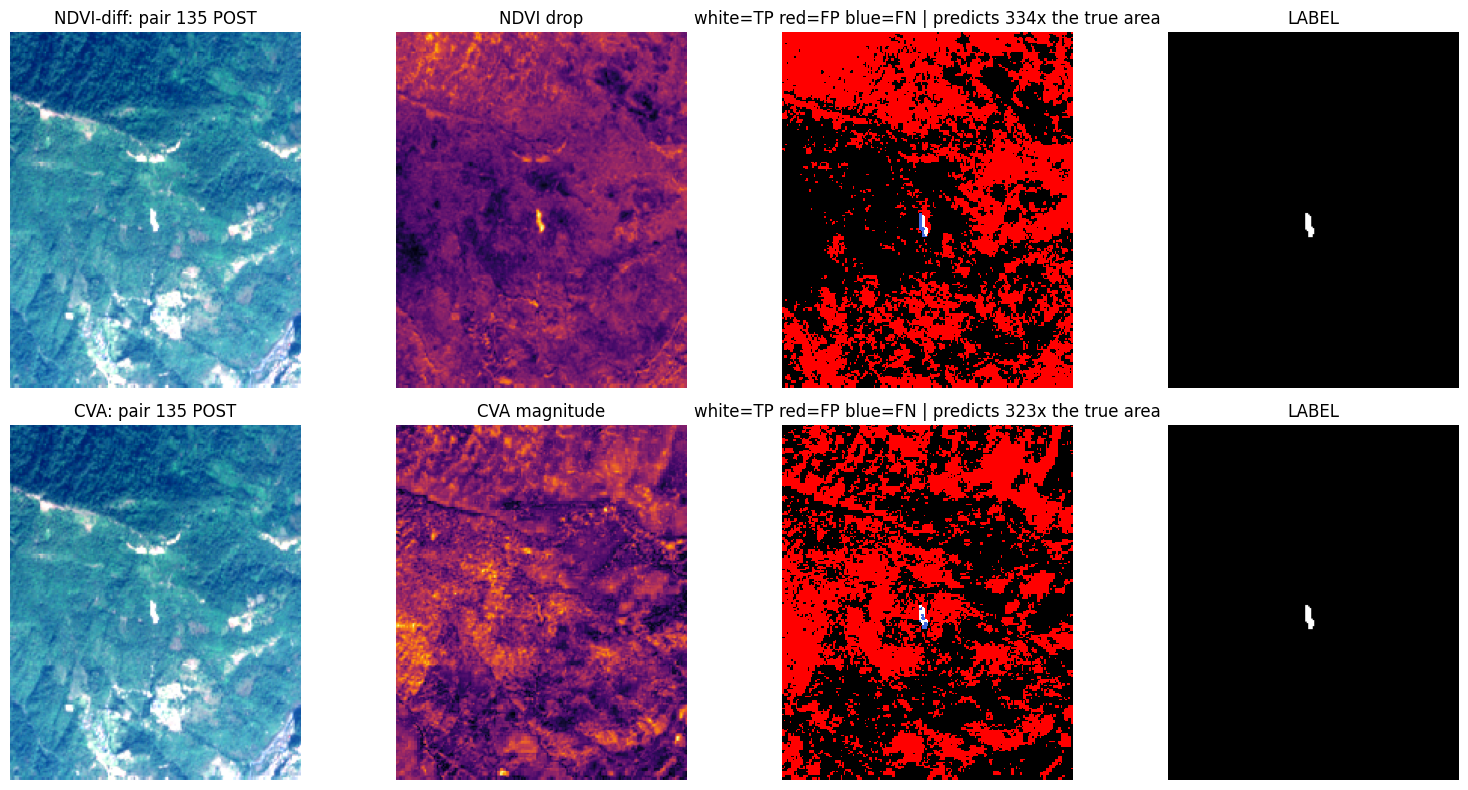

In [ ]:
# @title 7.1 False-positive analysis of the unsupervised baselines
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

LOW_NDVI = 0.2          # "already non-vegetated before the event"
fp_rows, store = [], {}

for pid in valid_ids:
    pre, _, h, w = read_scene(lp.loc[pid, "pre"])
    post, _, _, _ = read_scene(lp.loc[pid, "post"])
    gt = load_label_resized(lp.loc[pid, "label"], h, w).astype(bool)
    valid = (np.isfinite(pre).all(0) & np.isfinite(post).all(0)
             & (pre.sum(0) != 0) & (post.sum(0) != 0))
    pre, post = np.nan_to_num(pre), np.nan_to_num(post)
    pre_ndvi = ndvi(pre)

    rgb = np.moveaxis(post[[3, 2, 1]], 0, -1)
    lo, hi = np.percentile(rgb, [2, 98])
    rgb = np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

    scores = {"NDVI-diff": pre_ndvi - ndvi(post),
              "CVA": np.linalg.norm((post - pre)[CVA_BANDS], axis=0)}
    for name, sc in scores.items():
        pred = (sc > threshold_otsu(sc[valid])) & valid
        tp = (pred & gt).sum()
        fp = pred & ~gt
        fp_rows.append({"pair_id": pid, "method": name,
                        "gt_pct": 100 * gt.mean(), "pred_pct": 100 * pred.mean(),
                        "precision": tp / pred.sum() if pred.sum() else np.nan,
                        "fp_px": int(fp.sum()),
                        "fp_lowndvi_px": int((fp & (pre_ndvi < LOW_NDVI)).sum())})
        store[(pid, name)] = (rgb, sc, pred, gt)

fp_df = pd.DataFrame(fp_rows)
fp_df["overprediction_x"] = fp_df["pred_pct"] / fp_df["gt_pct"]
fp_df.to_csv(OUTPUT_DIR + "/baseline_false_positives.csv", index=False)

print("OVER-PREDICTION BY METHOD (16 pairs)")
summary = fp_df.groupby("method").agg(
    mean_gt_pct=("gt_pct", "mean"), mean_pred_pct=("pred_pct", "mean"),
    median_overprediction_x=("overprediction_x", "median"),
    mean_precision=("precision", "mean"),
    fp_px=("fp_px", "sum"), fp_lowndvi_px=("fp_lowndvi_px", "sum")).round(2)
summary["share_fp_already_low_NDVI_%"] = (100 * summary["fp_lowndvi_px"] / summary["fp_px"]).round(1)
display(summary)

# ---- Worst over-predicting pair for each method: POST | score | prediction | label ----
cmap = ListedColormap(["black", "white", "red", "royalblue"])   # none, TP, FP, FN
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for r, name in enumerate(["NDVI-diff", "CVA"]):
    sub = fp_df[(fp_df["method"] == name) & (fp_df["gt_pct"] > 0)]
    pid = sub.loc[sub["overprediction_x"].idxmax(), "pair_id"]
    rgb, sc, pred, gt = store[(pid, name)]
    cls = np.zeros(gt.shape, dtype=int)
    cls[pred & gt] = 1
    cls[pred & ~gt] = 2
    cls[~pred & gt] = 3
    row = sub[sub["pair_id"] == pid].iloc[0]
    axes[r, 0].imshow(rgb)
    axes[r, 0].set_title(f"{name}: pair {pid} POST")
    axes[r, 1].imshow(sc, cmap="inferno")
    axes[r, 1].set_title("NDVI drop" if name == "NDVI-diff" else "CVA magnitude")
    axes[r, 2].imshow(cls, cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
    axes[r, 2].set_title(f"white=TP red=FP blue=FN | predicts {row['overprediction_x']:.0f}x the true area")
    axes[r, 3].imshow(gt, cmap="gray", vmin=0, vmax=1)
    axes[r, 3].set_title("LABEL")
    for a in axes[r]:
        a.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/false_positive_panels.png", dpi=200)
plt.show()


### 7.2 Do the acquisition dates and landslide size track performance?
Uses the event dates from section 1.8. With 16 pairs, treat all correlations as indicative only.

In [ ]:
# @title 7.2 Do the pre/post dates and landslide size track performance?
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ---- Labelled pairs: dates, South Asia flag, and scores ----
lab_ids = labelled_pairs["pair_id"].astype(str).tolist()
lab = m[m["pair_id"].isin(lab_ids)].copy()
ef = results_df[results_df["model"] == "EarlyFusion"].set_index("pair_id")["IoU"]
sm = results_df[results_df["model"] == "Siamese"].set_index("pair_id")["IoU"]
lab["EarlyFusion_IoU"] = lab["pair_id"].map(ef)
lab["Siamese_IoU"] = lab["pair_id"].map(sm)
lab["changed_pct"] = lab["pair_id"].map(pair_stats_df.set_index(pair_stats_df["pair_id"].astype(str))["changed_pct"])

print("\nLABELLED PAIRS WITH EVENT DATES (pair 140 has no scores: excluded for misregistration)")
display(lab[["pair_id", "country", "source", "category", "event_date", "pre2", "post1",
             "pre_post_gap_d", "event_to_post_d", "south_asia", "changed_pct",
             "EarlyFusion_IoU", "Siamese_IoU"]]
        .sort_values("pair_id", key=lambda s: s.astype(int)).round(3).reset_index(drop=True))

# ---- Does the date choice track performance? (n is small; treat as indicative) ----
print("\nSPEARMAN CORRELATION WITH EarlyFusion IoU (16 pairs, indicative only)")
sc = lab.dropna(subset=["EarlyFusion_IoU"])
for col in ["pre_post_gap_d", "event_to_post_d", "pre_to_event_d", "changed_pct"]:
    s = sc.dropna(subset=[col])
    rho, p = spearmanr(s[col], s["EarlyFusion_IoU"])
    print(f"  {col:16s} rho={rho:+.2f}  p={p:.2f}  n={len(s)}")

print("\nSOUTH ASIA, LABELLED AND SCORED:")
display(sc[sc["south_asia"]][["pair_id", "country", "event_date", "pre2", "post1",
                              "pre_post_gap_d", "changed_pct", "EarlyFusion_IoU"]].round(3))

m.to_csv(OUTPUT_DIR + "/event_catalogue_analysis.csv", index=False)
print("\nSaved:", OUTPUT_DIR + "/event_catalogue_analysis.csv")



LABELLED PAIRS WITH EVENT DATES (pair 140 has no scores: excluded for misregistration)


,pair_id,country,source,category,event_date,pre2,post1,pre_post_gap_d,event_to_post_d,south_asia,changed_pct,EarlyFusion_IoU,Siamese_IoU
0,2,United States,GLC,landslide,2017-05-20,2017-05-17,2017-05-27,10.0,7.0,False,5.855,0.567,0.462
1,36,United States,GLC,landslide,2018-06-07,2018-06-01,2018-07-21,50.0,44.0,False,0.751,0.432,0.365
2,41,India,GLC,mudslide,2018-08-16,2018-05-07,2018-10-24,170.0,69.0,True,1.672,0.286,0.147
3,42,India,GLC,landslide,2018-08-18,2018-04-14,2018-09-11,150.0,24.0,True,0.328,0.032,0.000
4,61,Italy,IFFI,landslide,2018-03-13,2017-04-14,2018-04-16,367.0,34.0,False,0.538,0.012,0.070
5,75,Italy,IFFI,debris_flow,2019-05-13,2018-06-30,2019-06-05,340.0,23.0,False,0.831,0.399,0.207
6,108,Italy,IFFI,rotational_translational_slide,2021-01-04,2020-04-23,2021-04-08,350.0,94.0,False,0.411,0.046,0.032
7,121,Italy,IFFI,landslide,2021-07-31,2021-07-30,2021-08-09,10.0,9.0,False,0.331,0.032,0.000
8,125,Ireland,Ireland,landslide,2017-08-22,2017-07-18,2018-07-03,350.0,315.0,False,2.707,0.051,0.186
9,128,Ireland,Ireland,landslide,2017-08-22,2017-07-18,2018-07-03,350.0,315.0,False,1.671,0.118,0.114



SPEARMAN CORRELATION WITH EarlyFusion IoU (16 pairs, indicative only)
  pre_post_gap_d   rho=-0.16  p=0.56  n=16
  event_to_post_d  rho=-0.07  p=0.79  n=16
  pre_to_event_d   rho=-0.01  p=0.96  n=16
  changed_pct      rho=+0.63  p=0.01  n=16

SOUTH ASIA, LABELLED AND SCORED:


,pair_id,country,event_date,pre2,post1,pre_post_gap_d,changed_pct,EarlyFusion_IoU
160,135,Nepal,2018-08-02,2018-05-11,2018-11-27,200.0,0.138,0.073
169,41,India,2018-08-16,2018-05-07,2018-10-24,170.0,1.672,0.286
170,42,India,2018-08-18,2018-04-14,2018-09-11,150.0,0.328,0.032



Saved: /content/GLAD4CD/processed/event_catalogue_analysis.csv


## 8. Reflection evidence map and export
| Reflection question | Evidence in this notebook |
|---|---|
| Why grouped validation, and the gap vs random split? | 5.1 (random vs grouped), 5.2 (event-level leakage) |
| How much variance is due to which pair was held out? | std across pairs in 4.1, per-pair tables in 4.1 and 5.2, seed-averaged comparisons in 6.1 |
| Which non-landslide changes cause false positives, and how could pre/post dates reduce them? | 7.1 (over-prediction and low-NDVI false positives), 1.8a (date gaps), 7.2 (dates vs performance) |
| Single-date vs pre/post change detection | 6.1 (POST-only vs early fusion), 6.2 (pre-training), 1.8a (extra data demands: two dates per event) |

In [ ]:
# @title 8. Final export of all outputs
import os, shutil

OUTPUT_ZIP = "/content/GLaD4CD_Results"
shutil.make_archive(OUTPUT_ZIP, "zip", OUTPUT_DIR)
print("Archive:", OUTPUT_ZIP + ".zip", f"({os.path.getsize(OUTPUT_ZIP + '.zip') / 1e6:.1f} MB)")
print("Download it from the Files panel in the Colab sidebar.")


Archive: /content/GLaD4CD_Results.zip (9.4 MB)
Download it from the Files panel in the Colab sidebar.
